# ✅ 11_validacao_camadas — Validação da entrega: Bronze, Silver e Gold
**Squad 2 · Dupla 3 · `ecommerce_pedidos`** · ferramenta de validação, **somente leitura** (não grava, não move e não apaga nada)

Prova, camada por camada, que o que foi gravado cumpre o plano (Passos 5, 6 e 7) e as regras da planilha.
Cada camada é **recalculada a partir da anterior**, com código próprio e não com o código que a gravou: se o número recalculado
não bater com o gravado, a verificação mostra onde. O `07_explorador_squad2` confere totais; este notebook confere **pedido a pedido**
e **recalcula os KPIs**.

**Requisitos verificados**

| Requisito | O que é verificado | Etapa |
|---|---|---|
| Passo 5 · Bronze sem transformação | linhas e valores de cada micro-lote iguais aos do `raw` | 2 |
| Passo 5 · auditoria e partição | `bronze_ingested_at` e `bronze_source_file` preenchidos; `ano/mes/dia/hora` iguais aos de `bronze_ingested_at`; gravação só em `append` | 2 |
| Regra 1 · colunas obrigatórias | as 6 colunas na Bronze, com os tipos do contrato da EDA; micro-lotes recusados e o motivo | 2 |
| Regra 2 · arquivo processado uma vez | cada micro-lote com uma única ingestão; cada pedido em um único destino da Silver | 2 e 3 |
| Passo 6 · Silver em `append` com `silver_processed_at` | coluna preenchida; histórico do Delta só com `append`; nenhum pedido perdido ou inventado | 3 |
| Passo 6 · limpeza e tratamento | status, pagamento, valores e datas iguais à Bronze tratada de novo | 3 |
| Regras 3, 4, 5 e 10 · quarentena | destino e motivo de cada pedido recalculados a partir da Bronze | 3 |
| Regra 6 · volume em 5 min | pedidos de cada janela deslizante, pico (> 9h e < 23h), X = 1 e situação; placar até o pedido mais recente ou, com o pipeline em dia, até o relógio | 4 |
| Regra 7 · ticket médio por pagamento | ticket da última hora, média histórica, desvio e alerta do Pix (> 30% abaixo) | 4 |
| Regra 8 · taxa de cancelamento | pedidos, cancelados e taxa de cada janela de 30 min (deslizante, uma a cada 5 min); alerta acima de 10% | 4 |
| Regra 9 · receita acumulada no dia | receita por dia, mesmo dia da semana anterior e alerta fora de ±30% | 4 |
| Alertas (regras 5 a 10) | todo KPI em alerta e todo micro-lote reprovado têm alerta publicado, uma única vez | 4 |
| Passo 7 · `overwrite` nos KPIs e `append` nos históricos | um único ciclo por placar; modo de cada gravação no Delta; janelas sem repetição | 4 |
| Passo 7 · SQL Server | cada tabela da Gold no banco com as mesmas linhas, ciclos e totais da Delta | 5 |

| Etapa | Conteúdo |
|---|---|
| 1 | Configuração, critérios da planilha e retrato fixo das tabelas |
| 2 | Bronze × raw |
| 3 | Silver e quarentena × Bronze |
| 4 | Gold × Silver |
| 5 | SQL Server × Gold |
| 6 | Visualização da camada Gold: arquivos, conteúdo, placares e alertas |
| 7 | Veredito por requisito |

Cada verificação vira uma linha do veredito: ✅ ok · ⚠️ pendência ou informativo (ex.: uma camada ainda não processou o último lote) ·
❌ dado inconsistente com o plano ou com a planilha.

## Etapa 1 — Configuração e retrato fixo
**Faz:** carrega o `00_setup_config` em modo rápido, o contrato da EDA e os critérios da planilha. Anota a versão atual de cada tabela Delta e
lê **essa versão** em todas as etapas: se o pipeline gravar no meio da validação, os números daqui não mudam.
Os critérios das regras 6 a 9 estão escritos de novo aqui, de propósito: a validação não reaproveita os parâmetros da Gold, senão um erro
num parâmetro passaria despercebido.
**Valida:** contrato carregado, Bronze e Silver existentes e orquestrador parado (rodando, as camadas continuam certas na versão lida,
mas o SQL Server pode mudar durante a Etapa 5).

In [0]:
VALIDACAO_COMPLETA = False

In [0]:
%run ./00_setup_config

# ⚙️ 00_setup_config — Configuração central
**Squad 2 · Dupla 3 · `ecommerce_pedidos`**

Prepara endereços, credenciais, conexões e funções usadas por todo o pipeline. **Não lê nem grava pedidos.**

Cada etapa **faz o trabalho e valida em seguida**: ✅ ok · ⚠️ aviso (segue) · ❌ erro (para e explica).

**Uso nos outros notebooks** (duas células; o `%run` fica sozinho):
```
VALIDACAO_COMPLETA = False
```
```
%run ./00_setup_config
```
Dependências em **Environment → Dependencies**: `azure-identity`, `azure-storage-file-datalake`.

## Etapa 1 — Ambiente e endereços
**Faz:** cria a função `checar` e guarda os nomes fixos do projeto.
**Valida:** se está no Databricks e se origem e destino são containers diferentes.

Modo de validação: RÁPIDA
✅ Rodando no Databricks
✅ Origem (raw) e destino (squad2) separados


## Etapa 2 — Credenciais
**Faz:** busca as 7 chaves no Secret Scope. Ficam só na memória (aparecem como `[REDACTED]` se impressas).
**Valida:** se o cofre existe, se nenhuma chave falta e se o host do SQL tem o formato certo.

✅ Cofre 'mercadata-ecommerce-pedidos' encontrado
✅ 7 credenciais carregadas (valores ocultos)
✅ SQL_HOST no formato do Azure SQL


...

✅ url_origem OK
✅ tabela_delta_existe OK (Bronze já existe)
✅ ler_metadata OK (None para anotação inexistente)
✅ versao_delta OK (Bronze na versão 68)
✅ trava_ativa OK (orquestrador parado)


## Etapa 6 — Funções do SQL Server
**Faz:** cria as funções de gravar e consultar o banco. Gravação pelo conector `sqlserver` (o `jdbc` é bloqueado no Serverless); leitura pelo `jdbc`.
**Valida:** se toda tabela recebe o schema `squad2`.

✅ Tabelas SQL vão para o schema 'squad2'


## Etapa 7 — Teste completo (só ao rodar este notebook direto)
**Faz e valida:** varre o `raw` · lê o micro-lote mais recente e confere colunas e tipos (regra 1) · grava e relê em `metadata/` · `SELECT 1` no SQL Server · confere se o schema `squad2` existe no banco.
No modo rápido (`%run`), é pulada. No fim, limpa as variáveis temporárias.

Teste completo pulado (modo rápido).
⚙️ 00_setup_config pronto para uso


In [0]:
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from decimal import Decimal
from functools import reduce
import numpy as np
from pyspark.sql import functions as F

AMOSTRA_ARQUIVOS = 50          # Etapa 2: micro-lotes mais recentes comparados valor a valor com o raw (0 = todos)
DOWNLOADS_SIMULTANEOS = 8      # downloads do raw e do _delta_log em paralelo
EXEMPLOS = 10                  # linhas de exemplo exibidas quando uma verificação falha
# Regras 5 e 10: a correção do 05 (alertas também nas últimas 24 h) entrou na revisão de 11/10. Micro-lote sem alerta processado antes
# desta data (UTC) é falha histórica registrada (⚠️); depois dela, é ❌. None = qualquer falha é ❌.
ALERTAS_CORRIGIDOS_EM = pd.Timestamp("2026-10-12 01:15")
# Regra 8: o 05 com janelas deslizantes entrou em 12/10 (depois das 21:00 UTC). Alerta da regra 8 gerado antes disso é das janelas fixas antigas
REGRA8_DESLIZANTE_DESDE = pd.Timestamp("2026-10-12 21:00")

contrato = ler_metadata("eda_raw") or {}
SCHEMA = contrato.get("schema", {})                                          # {coluna: tipo} publicado pela EDA
FUSO_HORAS = int((contrato.get("fuso") or {}).get("horas_ate_utc", 0))       # horas que a Silver soma para levar as datas a UTC
STATUS_PERMITIDOS = (contrato.get("enums") or {}).get("status_pedido", [])    # regra 5
WATERMARK = pd.Timedelta(seconds=int((contrato.get("gold") or {}).get("watermark_s") or 120))
BRASILIA = pd.Timedelta(hours=3)                                             # UTC -> Brasília (sem horário de verão)

# Critérios da planilha e parâmetros do negócio (escritos de novo de propósito: não vêm da Gold)
CRITERIOS = {
    "x_regra6": 1, "pico_inicio_h": 9, "pico_fim_h": 23, "placar_volume_h": 2,                         # regra 6 (X proposto pela dupla)  
    "atraso_pipeline_s": 300, "minutos_minimos_alerta_regra6": 10,                                       # regra 6: relógio e episódio mínimo
    "janela_ticket_min": 60, "metodo_monitorado": "pix", "queda_pix_pct": 30,                           # regra 7
    "janela_cancelamento": "30min", "passo_cancelamento": "5min", "cancelamento_max_pct": 10, "placar_cancelamento_h": 24,
    "status_cancelado": "CANCELADO", "min_pedidos_cancelamento": 1,                                     # regra 8: "qualquer janela de 30 min"
    "variacao_receita_pct": 30, "dias_placar_receita": 14,                                              # regra 9 (±30% decidido com o Geovany)
}
KPIS = ["gold_kpi_volume_pedidos_5min", "gold_kpi_ticket_medio_pagamento", "gold_kpi_taxa_cancelamento_30min", "gold_kpi_receita_dia"]
HISTORICOS = ["gold_hist_volume_pedidos_5min", "gold_hist_ticket_medio_pagamento", "gold_hist_taxa_cancelamento_30min",
              "gold_hist_receita_dia", "gold_alertas"]

validacao = []
def registrar(etapa, requisito, verificacao, resultado, ok, critico=True):
    """Uma linha do veredito: ✅ ok · ❌ dado inconsistente (critico) · ⚠️ pendência ou informativo (não crítico)."""
    situacao = "✅" if ok else ("❌" if critico else "⚠️")
    validacao.append({"etapa": etapa, "requisito": requisito, "verificacao": verificacao, "resultado": str(resultado), "situacao": situacao})
    print(f"{situacao} {requisito} · {verificacao}: {resultado}")


def difere(a, b, tolerancia=0.0):
    """True se os valores diferem: vazio só é igual a vazio; números com tolerância; texto e data por igualdade."""
    vazio_a = a is None or (not isinstance(a, str) and pd.isna(a))
    vazio_b = b is None or (not isinstance(b, str) and pd.isna(b))
    if vazio_a or vazio_b:
        return vazio_a != vazio_b
    if isinstance(a, (int, float, Decimal, np.integer, np.floating)) and isinstance(b, (int, float, Decimal, np.integer, np.floating)):
        return abs(float(a) - float(b)) > tolerancia + 1e-9
    return a != b


def retrato(caminho):
    """(DataFrame na versão atual, versão); (None, -1) se a tabela ainda não existe. A versão lida vale para todas as etapas."""
    versao = versao_delta(caminho)
    return (ler_delta(caminho, versao), versao) if versao >= 0 else (None, -1)


def gravacoes(caminho):
    """Versão, operação, modo, momento (UTC) e linhas gravadas de cada commit do _delta_log, lidos direto dos arquivos."""
    pasta = f"{caminho.split(HOST_ADLS + '/', 1)[1]}/_delta_log"
    commits = [p.name for p in fs_squad.get_paths(path=pasta, recursive=False) if re.fullmatch(r"\d{20}\.json", p.name.rsplit("/", 1)[-1])]

    def ler(commit):
        versao = int(commit.rsplit("/", 1)[-1][:20])
        for registro in fs_squad.get_file_client(commit).download_file().readall().decode().splitlines():
            info = json.loads(registro).get("commitInfo") if registro.strip() else None
            if info:
                return (versao, info.get("operation"), str((info.get("operationParameters") or {}).get("mode", "")).lower(),
                        pd.to_datetime(info.get("timestamp"), unit="ms"), (info.get("operationMetrics") or {}).get("numOutputRows"),
                        info.get("userMetadata") or "")
        return versao, None, "", None, None, ""

    with ThreadPoolExecutor(DOWNLOADS_SIMULTANEOS) as pool:
        linhas = list(pool.map(ler, commits))
    return pd.DataFrame(linhas, columns=["versao", "operacao", "modo", "momento_utc", "linhas", "marca"]).sort_values("versao", ignore_index=True)


def conferir_modo(etapa, requisito, nome, caminho, modo_certo):
    """Modo das gravações no Delta: ❌ se a última gravação (o código atual) usa o modo errado; ⚠️ se só gravações antigas usaram.
    Gravação marcada como reparo (userMetadata "reprocesso...", 12_reprocessar_status) é ⚠️ e nunca ❌: é um reparo manual, registrado no commit."""
    escritas = gravacoes(caminho).query("operacao == 'WRITE'")
    if escritas.empty:
        return registrar(etapa, requisito, f"{nome}: modo das gravações", "nenhuma gravação no _delta_log", False, critico=False)
    erradas = escritas[escritas["modo"] != modo_certo]
    quando = lambda r: f" em {r.momento_utc:%d/%m %H:%M} UTC" if pd.notna(r.momento_utc) else ""
    quantas = lambda r: f" ({int(r.linhas):,} linhas)".replace(",", ".") if pd.notna(r.linhas) and str(r.linhas).isdigit() else ""
    detalhe = [f"v{r.versao} {r.modo or '?'}{quando(r)}{quantas(r)}" + (f" [{r.marca}]" if r.marca else "") for r in erradas.tail(5).itertuples()]
    resultado = (f"{len(escritas)} gravações, todas em {modo_certo}" if erradas.empty
                 else f"{len(erradas)} de {len(escritas)} fora de {modo_certo}: " + "; ".join(detalhe))
    erradas = erradas["versao"].tolist()
    registrar(etapa, requisito, f"{nome}: gravações só em {modo_certo}", resultado, not erradas,
              critico=escritas["modo"].iloc[-1] != modo_certo and not str(escritas["marca"].iloc[-1]).startswith("reprocesso"))


# Retrato fixo: cada tabela é lida numa única versão, usada em todas as etapas
bronze, v_bronze = retrato(CAMINHO_BRONZE)
silver, v_silver = retrato(CAMINHO_SILVER)
quarentena, v_quarentena = retrato(CAMINHO_QUARANTINE)
_lidas = {nome: retrato(caminho_gold(nome)) for nome in KPIS + HISTORICOS}
gold = {nome: df for nome, (df, _) in _lidas.items()}
versoes = {"bronze": v_bronze, "silver": v_silver, "quarantine": v_quarentena, **{nome: v for nome, (_, v) in _lidas.items()}}

# ------------------------------ validação ------------------------------
checar(bool(SCHEMA) and bool(STATUS_PERMITIDOS), f"Contrato da EDA carregado ({len(SCHEMA)} colunas, {len(STATUS_PERMITIDOS)} status permitidos)",
       "Contrato da EDA sem schema ou sem a lista de status: rode o 02_eda_ecommerce antes")
checar(bronze is not None and silver is not None, "Bronze e Silver encontradas", "Bronze ou Silver inexistente: rode o pipeline antes")
_dono = trava_ativa()
checar(_dono is None, "Orquestrador parado: nada muda durante a validação",
       f"Orquestrador {_dono} rodando: as camadas foram lidas numa versão fixa, mas o SQL Server pode mudar durante a Etapa 5", parar=False)

# ------------------------------ resultado ------------------------------
display(pd.DataFrame(list(versoes.items()), columns=["tabela", "versao_lida"]))

✅ Contrato da EDA carregado (10 colunas, 8 status permitidos)
✅ Bronze e Silver encontradas
✅ Orquestrador parado: nada muda durante a validação


tabela,versao_lida
bronze,68
silver,59
quarantine,43
gold_kpi_volume_pedidos_5min,333
gold_kpi_ticket_medio_pagamento,333
gold_kpi_taxa_cancelamento_30min,333
gold_kpi_receita_dia,333
gold_hist_volume_pedidos_5min,301
gold_hist_ticket_medio_pagamento,333
gold_hist_taxa_cancelamento_30min,15


## Etapa 2 — Bronze × raw (Passo 5 · regras 1 e 2)
### 2.1 Estrutura, auditoria e regra 2
**Faz:** cruza a lista do `raw` com a Bronze e com os recusados (`bronze_ignorados.json`); confere schema, colunas de auditoria,
partição, ingestões por micro-lote e o modo de cada gravação no Delta.
Daqui em diante, como a Silver, a validação usa só a **1ª ingestão** de cada micro-lote.
**Valida:** as 6 colunas obrigatórias com os tipos do contrato; auditoria preenchida; `ano/mes/dia/hora` iguais aos de `bronze_ingested_at`;
uma ingestão por micro-lote; Bronze só em `append`. Arquivo do `raw` ainda sem destino e arquivo recusado são ⚠️ (o motivo aparece abaixo).

In [0]:
no_raw = set(listar_arquivos_origem())
recusados = ler_metadata("bronze_ignorados") or {}
por_arquivo = (bronze.groupBy("bronze_source_file")
               .agg(F.countDistinct("bronze_ingested_at").alias("ingestoes"), F.count("*").alias("linhas")).toPandas())
na_bronze = set(por_arquivo["bronze_source_file"].dropna())
sem_destino = sorted(no_raw - na_bronze - set(recusados))
fantasmas = sorted(na_bronze - no_raw)
repetidos = por_arquivo[por_arquivo["ingestoes"] > 1]
tipos_bronze = dict(bronze.dtypes)
faltam = [c for c in COLUNAS_OBRIGATORIAS if c not in tipos_bronze]
divergentes = {c: tipos_bronze.get(c, "ausente") for c, t in SCHEMA.items() if tipos_bronze.get(c) != t}

particao_diferente = reduce(lambda a, b: a | b, [~F.col(c).eqNullSafe(f("bronze_ingested_at")) for c, f in
                                                 (("ano", F.year), ("mes", F.month), ("dia", F.dayofmonth), ("hora", F.hour))])
estrutura = bronze.agg(
    F.count("*").alias("linhas"),
    F.sum((F.col("bronze_ingested_at").isNull() | F.col("bronze_source_file").isNull()).cast("int")).alias("auditoria_vazia"),
    F.sum(particao_diferente.cast("int")).alias("particao_errada")).first().asDict()

# Regra 2 na leitura: só a 1ª ingestão de cada micro-lote segue para as próximas etapas, como faz a Silver
primeira = bronze.groupBy("bronze_source_file").agg(F.min("bronze_ingested_at").alias("bronze_ingested_at"))
bronze_1a = bronze.join(primeira, ["bronze_source_file", "bronze_ingested_at"], "left_semi")

# ------------------------------ validação ------------------------------
registrar(2, "Regra 1 · schema", "colunas obrigatórias na Bronze", ", ".join(faltam) or f"as {len(COLUNAS_OBRIGATORIAS)} presentes", not faltam)
registrar(2, "Regra 1 · schema", "tipos iguais aos do contrato da EDA", divergentes or "todos", not divergentes)
registrar(2, "Regra 1 · schema", "micro-lotes recusados pela Bronze (motivos abaixo)", len(recusados), not recusados, critico=False)
registrar(2, "Regra 2 · uma vez só", "micro-lotes com mais de uma ingestão na Bronze", len(repetidos), repetidos.empty)
registrar(2, "Passo 5 · Bronze", "linhas sem bronze_ingested_at ou bronze_source_file", estrutura["auditoria_vazia"] or 0,
          not estrutura["auditoria_vazia"])
registrar(2, "Passo 5 · Bronze", "linhas com ano/mes/dia/hora diferentes de bronze_ingested_at", estrutura["particao_errada"] or 0,
          not estrutura["particao_errada"])
registrar(2, "Passo 5 · Bronze", "micro-lotes do raw ainda sem destino (entram na próxima rodada)", len(sem_destino), not sem_destino, critico=False)
registrar(2, "Passo 5 · Bronze", "micro-lotes na Bronze que não existem mais no raw", len(fantasmas), not fantasmas, critico=False)
conferir_modo(2, "Passo 5 · Bronze", "Bronze", CAMINHO_BRONZE, "append")

# ------------------------------ resultado ------------------------------
print(f"raw: {len(no_raw)} micro-lotes · Bronze: {len(na_bronze)} micro-lotes, {estrutura['linhas']:,} linhas · recusados: {len(recusados)}")
if recusados:
    display(pd.DataFrame(list(recusados.items()), columns=["arquivo", "motivo"]))
if len(repetidos):
    display(repetidos.head(EXEMPLOS))

✅ Regra 1 · schema · colunas obrigatórias na Bronze: as 6 presentes
✅ Regra 1 · schema · tipos iguais aos do contrato da EDA: todos
✅ Regra 1 · schema · micro-lotes recusados pela Bronze (motivos abaixo): 0
✅ Regra 2 · uma vez só · micro-lotes com mais de uma ingestão na Bronze: 0
✅ Passo 5 · Bronze · linhas sem bronze_ingested_at ou bronze_source_file: 0
✅ Passo 5 · Bronze · linhas com ano/mes/dia/hora diferentes de bronze_ingested_at: 0
✅ Passo 5 · Bronze · micro-lotes do raw ainda sem destino (entram na próxima rodada): 0
✅ Passo 5 · Bronze · micro-lotes na Bronze que não existem mais no raw: 0
⚠️ Passo 5 · Bronze · Bronze: gravações só em append: 1 de 69 fora de append: v31 overwrite em 08/10 18:28 UTC (1.946 linhas)
raw: 379 micro-lotes · Bronze: 379 micro-lotes, 2,375 linhas · recusados: 0


### 2.2 Valores iguais ao `raw` (sem transformação)
**Faz:** baixa os `AMOSTRA_ARQUIVOS` micro-lotes mais recentes e compara, linha a linha e valor a valor, o arquivo original com o que está na Bronze.
O original passa só pelas conversões técnicas que a Bronze também faz: coluna opcional ausente entra vazia, datas truncadas em microssegundos
(limite do Spark) e data em texto ISO 8601 lida como data. Qualquer outra diferença é transformação, o que o Passo 5 proíbe.
**Valida:** cada micro-lote comparado tem as mesmas linhas com os mesmos valores nos dois lados.

In [0]:
def preparar_raw(pdf):
    """Arquivo original com só as conversões técnicas da Bronze (coluna ausente vazia; texto ISO 8601 -> data; data com fuso -> UTC)."""
    pdf = pdf.reindex(columns=list(SCHEMA))
    for coluna, tipo in SCHEMA.items():
        valores = pdf[coluna]
        if tipo != "timestamp":
            continue
        if valores.dtype.kind == "O" and valores.notna().any():
            try:
                datas = pd.to_datetime(valores, errors="coerce")
                pdf[coluna] = datas.dt.tz_convert("America/Sao_Paulo").dt.tz_localize(None) if datas.dt.tz else datas
            except (ValueError, TypeError, AttributeError):
                pass                                        # formato que a Bronze recusaria: a diferença aparece na comparação
        elif getattr(valores.dtype, "tz", None) is not None:
            pdf[coluna] = valores.dt.tz_convert("UTC").dt.tz_localize(None)
    return pdf


def normalizar(valor):
    """Valor comparável entre pandas (raw) e Spark (Bronze): vazio -> None; número -> 6 casas; data -> ISO em microssegundos."""
    if isinstance(valor, str):
        return valor
    if valor is None or pd.isna(valor):
        return None
    if isinstance(valor, (pd.Timestamp, np.datetime64)) or hasattr(valor, "isoformat"):
        return pd.Timestamp(valor).floor("us").isoformat()          # o Spark guarda datas em microssegundos
    if isinstance(valor, (int, float, Decimal, np.integer, np.floating)):
        return f"{float(valor):.6f}"
    return str(valor)


def baixar(caminho):
    return caminho, pd.read_parquet(io.BytesIO(fs_origem.get_file_client(caminho).download_file().readall()))


linhas_de = lambda pdf: Counter(tuple(normalizar(v) for v in linha) for linha in pdf[list(SCHEMA)].itertuples(index=False, name=None))
comparaveis = sorted(na_bronze & no_raw)                         # AAAA/MM/DD/HHMMSS: ordem alfabética = ordem de chegada
amostra = comparaveis[-AMOSTRA_ARQUIVOS:] if AMOSTRA_ARQUIVOS else comparaveis
with ThreadPoolExecutor(DOWNLOADS_SIMULTANEOS) as pool:
    originais = dict(pool.map(baixar, amostra))
gravados = bronze_1a.filter(F.col("bronze_source_file").isin(amostra)).select("bronze_source_file", *SCHEMA).toPandas()

diferencas = []
for caminho in amostra:
    original = linhas_de(preparar_raw(originais[caminho]))
    na_camada = linhas_de(gravados[gravados["bronze_source_file"] == caminho])
    if original != na_camada:
        diferencas.append({"arquivo": caminho, "linhas_raw": sum(original.values()), "linhas_bronze": sum(na_camada.values()),
                           "so_no_raw": sum((original - na_camada).values()), "so_na_bronze": sum((na_camada - original).values())})
del originais, gravados

# ------------------------------ validação ------------------------------
registrar(2, "Passo 5 · Bronze", f"valores iguais ao raw, sem transformação ({len(amostra)} micro-lotes mais recentes)",
          f"{len(amostra) - len(diferencas)} de {len(amostra)} idênticos", not diferencas)

# ------------------------------ resultado ------------------------------
if diferencas:
    display(pd.DataFrame(diferencas).head(EXEMPLOS))

✅ Passo 5 · Bronze · valores iguais ao raw, sem transformação (50 micro-lotes mais recentes): 50 de 50 idênticos


## Etapa 3 — Silver e quarentena × Bronze (Passo 6 · regras 2, 3, 4, 5 e 10)
**Faz:** pega na Bronze os pedidos que a Silver já deveria ter processado (1ª ingestão de cada micro-lote, até a marca d'água do
`silver_controle.json`) e, para cada pedido (chave: `id_pedido` + micro-lote):

| Passo | Pergunta |
|---|---|
| 3.1 | Está em **exatamente um** destino, Silver ou quarentena? |
| 3.2 | O destino e o motivo batem com as regras 3, 4, 5 e 10 recalculadas a partir do valor da Bronze? |
| 3.3 | As colunas tratadas batem com o tratamento do Passo 6 refeito a partir da Bronze? |

| Regra | Reprova quando |
|---|---|
| 3 | `valor_total` vazio ou ≤ 0, já em `DECIMAL(12,2)` (o tipo decimal pedido pela regra) |
| 4 | `dt_pedido` vazio |
| 5 | `status_pedido` (maiúsculo, sem espaços nas pontas) vazio ou fora da lista do contrato |
| 10 | `dt_ultima_atualizacao_status` < `dt_pedido` |

| Coluna | Tratamento esperado |
|---|---|
| `status_pedido` / `metodo_pagamento` | maiúsculas / minúsculas, sem espaços nas pontas |
| `valor_total`, `valor_frete` | `DECIMAL(12,2)` |
| `dt_pedido`, `dt_previsao_entrega`, `dt_ultima_atualizacao_status` | Bronze + fuso do contrato (UTC) |
| `data_pedido_local` | dia do `dt_pedido` original (Brasília) |

Pedido ingerido depois da marca d'água é pendência (⚠️: a Silver ainda não rodou para ele), não erro.
**Valida:** nenhum pedido perdido, repetido ou inventado; destino, motivo e colunas tratadas iguais ao recálculo; `silver_processed_at`
preenchido; Silver e quarentena gravadas só em `append`.

In [0]:
marca = (ler_metadata("silver_controle") or {}).get("marca_dagua")
destinos = reduce(lambda a, b: a.unionByName(b, allowMissingColumns=True),
                  [df.withColumn("destino", F.lit(nome)) for nome, df in (("silver", silver), ("quarentena", quarentena)) if df is not None])
if "motivo_quarentena" not in destinos.columns:                              # quarentena ainda vazia
    destinos = destinos.withColumn("motivo_quarentena", F.lit(None).cast("string"))

chave = F.concat_ws("|", F.coalesce(F.col("id_pedido").cast("string"), F.lit("vazio")), F.col("bronze_source_file"))
ate_marca = (F.col("bronze_ingested_at") <= F.to_timestamp(F.lit(marca))) if marca else F.lit(False)

# 3.1 Regra 2: cada pedido da Bronze em exatamente um destino
contagem = (bronze_1a.groupBy(chave.alias("chave")).agg(F.count("*").alias("na_bronze"), F.max(ate_marca.cast("int")).alias("ate_marca"))
            .join(destinos.groupBy(chave.alias("chave")).agg(F.count("*").alias("nos_destinos")), "chave", "full")
            .fillna(0, ["na_bronze", "nos_destinos", "ate_marca"]))
c31 = contagem.agg(
    F.sum((F.col("ate_marca") == 1).cast("int")).alias("processados"),
    F.sum(((F.col("ate_marca") == 1) & (F.col("nos_destinos") == 0)).cast("int")).alias("perdidos"),
    F.sum(((F.col("na_bronze") > 0) & (F.col("nos_destinos") > 0) & (F.col("nos_destinos") != F.col("na_bronze"))).cast("int")).alias("repetidos"),
    F.sum(((F.col("na_bronze") == 0) & (F.col("nos_destinos") > 0)).cast("int")).alias("sem_origem"),
    F.sum(((F.col("na_bronze") > 0) & (F.col("ate_marca") == 0) & (F.col("nos_destinos") == 0)).cast("int")).alias("pendentes"),
).first().asDict()

# 3.2 e 3.3: regras e tratamento refeitos a partir da Bronze, com código próprio
VALOR = lambda c: F.expr(f"try_cast({c} AS DECIMAL(12,2))")
STATUS = F.upper(F.trim("status_pedido"))
REGRAS_SILVER = {
    "regra3_valor_total_nao_positivo": VALOR("valor_total").isNull() | (VALOR("valor_total") <= 0),
    "regra4_dt_pedido_invalida": F.col("dt_pedido").isNull(),
    "regra5_status_fora_do_enum": STATUS.isNull() | ~STATUS.isin(STATUS_PERMITIDOS),
    "regra10_atualizacao_antes_do_pedido": F.col("dt_ultima_atualizacao_status") < F.col("dt_pedido"),
}
para_utc = lambda c: F.col(c) + F.expr(f"INTERVAL {FUSO_HORAS} HOURS")
TRATAMENTO = {
    "id_cliente": F.col("id_cliente"), "id_endereco_entrega": F.col("id_endereco_entrega"),
    "status_pedido": STATUS, "metodo_pagamento": F.lower(F.trim("metodo_pagamento")),
    "valor_total": VALOR("valor_total"), "valor_frete": VALOR("valor_frete"),
    "dt_pedido": para_utc("dt_pedido"), "dt_previsao_entrega": para_utc("dt_previsao_entrega"),
    "dt_ultima_atualizacao_status": para_utc("dt_ultima_atualizacao_status"), "data_pedido_local": F.to_date("dt_pedido"),
}
motivo_ordenado = lambda lista: F.concat_ws(", ", F.array_sort(lista))       # "" quando não há motivo
esperado = bronze_1a.filter(ate_marca).select(
    chave.alias("chave"), *[e.alias(f"esperado_{c}") for c, e in TRATAMENTO.items()],
    motivo_ordenado(F.array(*[F.when(cond, F.lit(nome)) for nome, cond in REGRAS_SILVER.items()])).alias("motivo_esperado"))
gravado = destinos.select(
    chave.alias("chave"), "destino", "silver_processed_at", *[F.col(c).alias(f"gravado_{c}") for c in TRATAMENTO],
    motivo_ordenado(F.split(F.coalesce("motivo_quarentena", F.lit("")), ", ")).alias("motivo_gravado"))
pares = esperado.join(gravado, "chave")

destino_errado = (F.col("motivo_esperado") == "") != (F.col("destino") == "silver")
motivo_errado = (F.col("destino") == "quarentena") & (F.col("motivo_esperado") != F.col("motivo_gravado"))
coluna_errada = {c: ~F.col(f"gravado_{c}").eqNullSafe(F.col(f"esperado_{c}")) for c in TRATAMENTO}
c32 = pares.agg(F.count("*").alias("pares"), F.sum(destino_errado.cast("int")).alias("destino_errado"),
                F.sum(motivo_errado.cast("int")).alias("motivo_errado"),
                F.sum(F.col("silver_processed_at").isNull().cast("int")).alias("sem_processed_at"),
                *[F.sum(cond.cast("int")).alias(c) for c, cond in coluna_errada.items()]).first().asDict()
colunas_erradas = {c: c32[c] for c in TRATAMENTO if c32[c]}
ids_repetidos = silver.groupBy("id_pedido").count().filter("count > 1").count()
tipo_valor = dict(silver.dtypes).get("valor_total", "ausente")

# ------------------------------ validação ------------------------------
registrar(3, "Regra 2 · uma vez só", "pedidos repetidos na Silver/quarentena ou nos dois destinos", c31["repetidos"] or 0, not c31["repetidos"])
registrar(3, "Passo 6 · Silver", f"pedidos processados ({c31['processados'] or 0:,}) fora da Silver e da quarentena", c31["perdidos"] or 0,
          not c31["perdidos"])
registrar(3, "Passo 6 · Silver", "pedidos na Silver/quarentena que não existem na Bronze", c31["sem_origem"] or 0, not c31["sem_origem"])
registrar(3, "Passo 6 · Silver", "pedidos da Bronze depois da marca d'água (rode a Silver)", c31["pendentes"] or 0, not c31["pendentes"],
          critico=False)
registrar(3, "Regras 3, 4, 5 e 10 · quarentena", f"pedidos no destino errado ({c32['pares']:,} conferidos)", c32["destino_errado"] or 0,
          not c32["destino_errado"])
registrar(3, "Regras 3, 4, 5 e 10 · quarentena", "motivos da quarentena diferentes do recálculo", c32["motivo_errado"] or 0,
          not c32["motivo_errado"])
registrar(3, "Passo 6 · Silver", f"tratamento refeito igual ao gravado ({len(TRATAMENTO)} colunas)", colunas_erradas or "todas iguais",
          not colunas_erradas)
registrar(3, "Passo 6 · Silver", "linhas sem silver_processed_at", c32["sem_processed_at"] or 0, not c32["sem_processed_at"])
registrar(3, "Regras 3, 4, 5 e 10 · quarentena", "valor_total da Silver em decimal (regra 3)", tipo_valor, tipo_valor.startswith("decimal"))
conferir_modo(3, "Passo 6 · Silver", "Silver", CAMINHO_SILVER, "append")
if quarentena is not None:
    conferir_modo(3, "Passo 6 · Silver", "quarentena", CAMINHO_QUARANTINE, "append")
registrar(3, "Passo 6 · Silver", "id_pedido em mais de um micro-lote (fora da planilha: só monitorado)", ids_repetidos, not ids_repetidos,
          critico=False)

# ------------------------------ resultado ------------------------------
display(pares.groupBy("destino", "motivo_gravado").count().orderBy(F.desc("count")))
problema = destino_errado | motivo_errado | reduce(lambda a, b: a | b, coluna_errada.values())
if c32["destino_errado"] or c32["motivo_errado"] or colunas_erradas:
    display(pares.filter(problema).limit(EXEMPLOS))

✅ Regra 2 · uma vez só · pedidos repetidos na Silver/quarentena ou nos dois destinos: 0
✅ Passo 6 · Silver · pedidos processados (2,375) fora da Silver e da quarentena: 0
✅ Passo 6 · Silver · pedidos na Silver/quarentena que não existem na Bronze: 0
✅ Passo 6 · Silver · pedidos da Bronze depois da marca d'água (rode a Silver): 0
✅ Regras 3, 4, 5 e 10 · quarentena · pedidos no destino errado (2,375 conferidos): 0
✅ Regras 3, 4, 5 e 10 · quarentena · motivos da quarentena diferentes do recálculo: 0
✅ Passo 6 · Silver · tratamento refeito igual ao gravado (10 colunas): todas iguais
✅ Passo 6 · Silver · linhas sem silver_processed_at: 0
✅ Regras 3, 4, 5 e 10 · quarentena · valor_total da Silver em decimal (regra 3): decimal(12,2)
✅ Passo 6 · Silver · Silver: gravações só em append: 60 gravações, todas em append
⚠️ Passo 6 · Silver · quarentena: gravações só em append: 1 de 44 fora de append: v43 overwrite em 16/10 02:38 UTC (208 linhas) [reprocesso_regra5]
✅ Passo 6 · Silver · id_pedido em

destino,motivo_gravado,count
silver,,2167
quarentena,regra10_atualizacao_antes_do_pedido,134
quarentena,regra5_status_fora_do_enum,41
quarentena,regra3_valor_total_nao_positivo,28
quarentena,"regra10_atualizacao_antes_do_pedido, regra5_status_fora_do_enum",4
quarentena,"regra10_atualizacao_antes_do_pedido, regra3_valor_total_nao_positivo",1


## Etapa 4 — Gold × Silver (Passo 7 · regras 5 a 10)
### 4.1 Retrato da Gold e referência
**Faz:** cada placar guarda o `ciclo_id` (UTC) em que foi calculado. A validação reconstrói a Silver como a Gold a leu naquele ciclo
(pedidos com `silver_processed_at` até o `ciclo_id`) e recalcula tudo a partir dela, no horário de Brasília.
O "agora" da Gold é o pedido mais recente (tempo do evento), gravado como fim da janela do ticket; só o placar da regra 6 pode andar
com o relógio (4.2).
**Valida:** um único ciclo por placar (`overwrite`); os 4 placares do mesmo ciclo; referência igual ao pedido mais recente da Silver
naquele ciclo; Gold rodada depois da última gravação da Silver (⚠️ se não: basta rodar o `05_ingestao_gold`).

In [0]:
placar = {nome: (gold[nome].toPandas() if gold[nome] is not None else pd.DataFrame()) for nome in KPIS}
checar(all(len(p) for p in placar.values()), "Os 4 placares da Gold encontrados", "Placar da Gold vazio ou inexistente: rode o 05_ingestao_gold antes")

_silver_no_ciclo = {}
def silver_no_ciclo(ciclo_id):
    """Pedidos aprovados que a Gold leu naquele ciclo (silver_processed_at até o fim do segundo do ciclo_id), em Brasília."""
    ciclo_id = int(ciclo_id)
    if ciclo_id not in _silver_no_ciclo:
        limite = pd.to_datetime(str(ciclo_id), format="%Y%m%d%H%M%S") + pd.Timedelta(seconds=1)
        pdf = (silver.filter(F.col("silver_processed_at") < F.lit(limite.to_pydatetime()))
               .select("dt_pedido", "status_pedido", F.col("valor_total").cast("double").alias("valor_total"), "metodo_pagamento").toPandas())
        pdf["dt_local"] = (pd.to_datetime(pdf["dt_pedido"]) - BRASILIA).astype("datetime64[ns]")
        _silver_no_ciclo[ciclo_id] = pdf.dropna(subset=["dt_local"]).sort_values("dt_local", ignore_index=True)
    return _silver_no_ciclo[ciclo_id]


para_ns = lambda serie: pd.to_datetime(serie).astype("datetime64[ns]")
ciclo_de = {nome: int(p["ciclo_id"].max()) for nome, p in placar.items()}
referencia = pd.Timestamp(para_ns(placar["gold_kpi_ticket_medio_pagamento"]["janela_fim"]).max())
mais_recente = silver_no_ciclo(ciclo_de["gold_kpi_ticket_medio_pagamento"])["dt_local"].max()
inicio_ultimo_ciclo = pd.to_datetime(str(max(ciclo_de.values())), format="%Y%m%d%H%M%S")
ultima_silver = silver.agg(F.max("silver_processed_at")).first()[0]
atrasada = ultima_silver is not None and pd.Timestamp(ultima_silver) >= inicio_ultimo_ciclo + pd.Timedelta(seconds=1)

# ------------------------------ validação ------------------------------
for nome, p in placar.items():
    registrar(4, "Passo 7 · Gold", f"{nome}: uma única fotografia (overwrite)", f"{p['ciclo_id'].nunique()} ciclo_id", p["ciclo_id"].nunique() == 1)
registrar(4, "Passo 7 · Gold", "os 4 placares são do mesmo ciclo", sorted(set(ciclo_de.values())), len(set(ciclo_de.values())) == 1, critico=False)
registrar(4, "Passo 7 · Gold", "referência = pedido mais recente da Silver naquele ciclo", f"Gold {referencia} · Silver {mais_recente}",
          referencia == mais_recente)
registrar(4, "Passo 7 · Gold", "Gold rodada depois da última gravação da Silver",
          f"último ciclo {inicio_ultimo_ciclo} UTC · última Silver {ultima_silver}", not atrasada, critico=False)

✅ Os 4 placares da Gold encontrados
✅ Passo 7 · Gold · gold_kpi_volume_pedidos_5min: uma única fotografia (overwrite): 1 ciclo_id
✅ Passo 7 · Gold · gold_kpi_ticket_medio_pagamento: uma única fotografia (overwrite): 1 ciclo_id
✅ Passo 7 · Gold · gold_kpi_taxa_cancelamento_30min: uma única fotografia (overwrite): 1 ciclo_id
✅ Passo 7 · Gold · gold_kpi_receita_dia: uma única fotografia (overwrite): 1 ciclo_id
✅ Passo 7 · Gold · os 4 placares são do mesmo ciclo: [20261016025738]
✅ Passo 7 · Gold · referência = pedido mais recente da Silver naquele ciclo: Gold 2026-10-15 11:05:56.050611 · Silver 2026-10-15 11:05:56.050611
✅ Passo 7 · Gold · Gold rodada depois da última gravação da Silver: último ciclo 2026-10-16 02:57:38 UTC · última Silver 2026-10-16 02:38:01.320813


### 4.2 Regra 6 · volume de pedidos em 5 minutos
**Faz:** descobre até onde vai o placar. Só há duas referências legítimas: o pedido mais recente da Silver naquele ciclo ou, quando a Gold usou o
relógio (pipeline em dia e sem pedido novo), o `ciclo_id` em Brasília menos o atraso do pipeline, e o relógio só vale se for posterior ao pedido
mais recente. Para cada janela do placar, conta de novo os pedidos com `início ≤ dt < fim` (zero nos minutos sem pedido); refaz o critério de pico
da planilha (janela inteira entre 9h e 23h) e a situação (`aberta` → `fora_do_pico` → `alerta` se abaixo de X → `normal`).
**Valida:** referência legítima; pedidos iguais em todas as janelas; placar cobrindo as 2 h até a referência, minuto a minuto; pico e situação
coerentes; X = 1. Janela fechada calculada com o *watermark* atual do contrato é ⚠️ se divergir (o contrato pode ter mudado depois do ciclo).

In [0]:
vol = placar["gold_kpi_volume_pedidos_5min"].copy()
base6 = silver_no_ciclo(ciclo_de["gold_kpi_volume_pedidos_5min"])
vol["janela_inicio"], vol["janela_fim"] = para_ns(vol["janela_inicio"]), para_ns(vol["janela_fim"])
vol = vol.sort_values("janela_inicio", ignore_index=True)
vol["fechada"], vol["no_pico"] = vol["fechada"].astype(bool), vol["no_pico"].astype(bool)

# Referência do placar: o pedido mais recente ou, se a Gold usou o relógio, o ciclo (UTC -> Brasília) menos o atraso do pipeline, se posterior
ref_pedido = base6["dt_local"].max()
ref_relogio = (pd.to_datetime(str(ciclo_de["gold_kpi_volume_pedidos_5min"]), format="%Y%m%d%H%M%S") - BRASILIA
               - pd.Timedelta(seconds=CRITERIOS["atraso_pipeline_s"]))
fim_gravado = vol["janela_fim"].max() - pd.Timedelta(minutes=1)                # último minuto do placar gravado
candidatas = ([("relógio", ref_relogio)] if ref_relogio > ref_pedido else []) + [("pedido mais recente", ref_pedido)]
modo6, ref6 = next(((m, r) for m, r in candidatas if r.floor("min") == fim_gravado), (None, ref_pedido))

tempos = base6["dt_local"].values                                             # ordenado: busca binária conta cada janela
vol["pedidos_recalculado"] = (np.searchsorted(tempos, vol["janela_fim"].values, side="left")
                              - np.searchsorted(tempos, vol["janela_inicio"].values, side="left"))
vol["no_pico_recalculado"] = ((vol["janela_inicio"].dt.hour >= CRITERIOS["pico_inicio_h"])
                              & (vol["janela_fim"] <= vol["janela_inicio"].dt.normalize() + pd.Timedelta(hours=CRITERIOS["pico_fim_h"])))
vol["fechada_recalculado"] = vol["janela_fim"] <= ref6 - WATERMARK
vol["situacao_esperada"] = np.select([~vol["fechada"], ~vol["no_pico"], vol["pedidos"] < vol["limite_x"]],
                                     ["aberta", "fora_do_pico", "alerta"], default="normal")
inicio_placar = ref6.floor("min") - pd.Timedelta(hours=CRITERIOS["placar_volume_h"])
continuo = bool((vol["janela_inicio"].diff().dropna() == pd.Timedelta(minutes=1)).all())
cobre = vol["janela_inicio"].min() == inicio_placar and vol["janela_fim"].max() == ref6.floor("min") + pd.Timedelta(minutes=1)
erro_pedidos = vol[vol["pedidos"] != vol["pedidos_recalculado"]]
erro_pico = vol[vol["no_pico"] != vol["no_pico_recalculado"]]
erro_situacao = vol[vol["situacao"] != vol["situacao_esperada"]]
erro_fechada = vol[vol["fechada"] != vol["fechada_recalculado"]]
valores_x = sorted(int(x) for x in vol["limite_x"].unique())

# ------------------------------ validação ------------------------------
registrar(4, "Regra 6 · volume 5 min", "referência do placar: pedido mais recente ou relógio (se posterior)",
          f"{modo6}: {ref6:%d/%m %H:%M:%S}" if modo6 else f"nenhuma das duas: o placar termina em {fim_gravado}", modo6 is not None)
registrar(4, "Regra 6 · volume 5 min", f"pedidos por janela iguais ao recálculo ({len(vol)} janelas)", f"{len(vol) - len(erro_pedidos)} de {len(vol)} iguais",
          erro_pedidos.empty)
registrar(4, "Regra 6 · volume 5 min", "placar cobre as 2 h até a referência, minuto a minuto, sem buracos",
          f"{vol['janela_inicio'].min()} a {vol['janela_fim'].max()}", continuo and cobre)
registrar(4, "Regra 6 · volume 5 min", "pico (> 9h e < 23h) igual ao da planilha", f"{len(erro_pico)} janelas divergentes", erro_pico.empty)
registrar(4, "Regra 6 · volume 5 min", "situação coerente com fechada, pico e X", f"{len(erro_situacao)} janelas divergentes", erro_situacao.empty)
registrar(4, "Regra 6 · volume 5 min", f"X igual ao proposto pela dupla ({CRITERIOS['x_regra6']})", valores_x,
          valores_x == [CRITERIOS["x_regra6"]], critico=False)
registrar(4, "Regra 6 · volume 5 min", f"janelas fechadas pelo watermark atual do contrato ({WATERMARK.total_seconds():.0f} s)",
          f"{len(erro_fechada)} janelas divergentes", erro_fechada.empty, critico=False)

# ------------------------------ resultado ------------------------------
print(f"Situação das janelas: {vol['situacao'].value_counts().to_dict()}")
divergentes6 = pd.concat([erro_pedidos, erro_pico, erro_situacao]).drop_duplicates("janela_inicio")
if len(divergentes6):
    display(divergentes6[["janela_inicio", "janela_fim", "pedidos", "pedidos_recalculado", "no_pico", "no_pico_recalculado",
                          "situacao", "situacao_esperada"]].head(EXEMPLOS))

✅ Regra 6 · volume 5 min · referência do placar: pedido mais recente ou relógio (se posterior): relógio: 15/10 23:52:38
✅ Regra 6 · volume 5 min · pedidos por janela iguais ao recálculo (117 janelas): 117 de 117 iguais
✅ Regra 6 · volume 5 min · placar cobre as 2 h até a referência, minuto a minuto, sem buracos: 2026-10-15 21:52:00 a 2026-10-15 23:53:00
✅ Regra 6 · volume 5 min · pico (> 9h e < 23h) igual ao da planilha: 0 janelas divergentes
✅ Regra 6 · volume 5 min · situação coerente com fechada, pico e X: 0 janelas divergentes
✅ Regra 6 · volume 5 min · X igual ao proposto pela dupla (1): [1]
✅ Regra 6 · volume 5 min · janelas fechadas pelo watermark atual do contrato (120 s): 0 janelas divergentes
Situação das janelas: {'alerta': 64, 'fora_do_pico': 50, 'aberta': 3}


### 4.3 Regra 7 · ticket médio por método de pagamento
**Faz:** para cada método, recalcula pedidos, receita e ticket da janela recente (última hora até a referência) e a média histórica
(pedidos anteriores à janela). A planilha só define alerta para o Pix: `alerta` se ficar **mais de** 30% abaixo da própria média histórica.
**Valida:** mesmos métodos; pedidos iguais; receita, ticket e média com diferença de até R$ 0,01; desvio até 0,1 p.p.; mesma situação.

In [0]:
tic = placar["gold_kpi_ticket_medio_pagamento"].copy()
base7 = silver_no_ciclo(ciclo_de["gold_kpi_ticket_medio_pagamento"])
ref7 = base7["dt_local"].max()
inicio7 = ref7 - pd.Timedelta(minutes=CRITERIOS["janela_ticket_min"])
dividir = lambda a, b: a / b if b else None

recalculo7 = []
for metodo, grupo in base7.groupby(base7["metodo_pagamento"].fillna("(vazio)")):
    janela, antes = grupo[grupo["dt_local"] > inicio7], grupo[grupo["dt_local"] <= inicio7]
    ticket, media = dividir(janela["valor_total"].sum(), len(janela)), dividir(antes["valor_total"].sum(), len(antes))
    desvio = None if ticket is None or not media else round((ticket / media - 1) * 100, 1)
    situacao = ("nao_monitorado" if metodo != CRITERIOS["metodo_monitorado"] else "sem_pedidos" if not len(janela)
                else "sem_historico" if desvio is None else "alerta" if desvio < -CRITERIOS["queda_pix_pct"] else "normal")
    recalculo7.append({"metodo_pagamento": metodo, "pedidos_r": len(janela), "receita_r": janela["valor_total"].sum() if len(janela) else None,
                       "ticket_medio_r": ticket, "media_historica_r": media, "desvio_pct_r": desvio, "situacao_r": situacao})
comp7 = (tic.assign(metodo_pagamento=tic["metodo_pagamento"].fillna("(vazio)"))
         .merge(pd.DataFrame(recalculo7), on="metodo_pagamento", how="outer", indicator=True))
TOLERANCIA7 = {"pedidos": 0, "receita": 0.01, "ticket_medio": 0.01, "media_historica": 0.01, "desvio_pct": 0.1}
ambos = comp7[comp7["_merge"] == "both"]
erro7 = {c: int(sum(difere(a, b, t) for a, b in zip(ambos[c], ambos[f"{c}_r"]))) for c, t in TOLERANCIA7.items()}
erro7["situacao"] = int((ambos["situacao"] != ambos["situacao_r"]).sum())
metodos_diferentes = comp7.loc[comp7["_merge"] != "both", "metodo_pagamento"].tolist()

# ------------------------------ validação ------------------------------
registrar(4, "Regra 7 · ticket médio", "mesmos métodos de pagamento no placar e no recálculo", metodos_diferentes or "iguais", not metodos_diferentes)
registrar(4, "Regra 7 · ticket médio", f"valores e situação iguais ao recálculo ({len(ambos)} métodos)",
          {c: n for c, n in erro7.items() if n} or "todos iguais", not any(erro7.values()))

# ------------------------------ resultado ------------------------------
display(comp7.drop(columns="_merge"))

✅ Regra 7 · ticket médio · mesmos métodos de pagamento no placar e no recálculo: iguais
✅ Regra 7 · ticket médio · valores e situação iguais ao recálculo (4 métodos): todos iguais


metodo_pagamento,janela_inicio,janela_fim,pedidos,receita,ticket_medio,media_historica,desvio_pct,situacao,ciclo_id,pedidos_r,receita_r,ticket_medio_r,media_historica_r,desvio_pct_r,situacao_r
boleto,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,21,4445.38,211.68,251.36,-15.8,nao_monitorado,20261016025738,21,4445.38,211.6847619047619,251.3604761904762,-15.8,nao_monitorado
cartão crédito,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,32,7967.0,248.97,255.95,-2.7,nao_monitorado,20261016025738,32,7967.0,248.96875,255.9468487394958,-2.7,nao_monitorado
cartão débito,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,28,7947.35,283.83,295.65,-4.0,nao_monitorado,20261016025738,28,7947.350000000001,283.8339285714286,295.6540798611111,-4.0,nao_monitorado
pix,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,32,8463.28,264.48,268.52,-1.5,normal,20261016025738,32,8463.28,264.4775,268.5167052023121,-1.5,normal


### 4.4 Regra 8 · taxa de cancelamento em janelas de 30 minutos
**Faz:** recalcula, nas últimas 24 h até a referência, pedidos e cancelados de cada janela **deslizante** de 30 min (uma começando a cada 5 min,
em múltiplos de 5 min, como o `window` do Spark) e a taxa. Cada pedido é contado, com código próprio, nas 6 janelas que o contêm.
Como na Gold, a primeira janela começa no primeiro múltiplo de 5 min dentro das 24 h (nenhuma fica pela metade) e janela sem pedido não aparece.
**Valida:** mesmas janelas; pedidos e cancelados iguais; taxa com diferença de até 0,01 p.p.; situação coerente (`aberta` ou, fechada,
`alerta` acima de 10% com o mínimo de pedidos, `poucos_pedidos` acima de 10% sem o mínimo, `normal`).

In [0]:
canc = placar["gold_kpi_taxa_cancelamento_30min"].copy()
base8 = silver_no_ciclo(ciclo_de["gold_kpi_taxa_cancelamento_30min"])
ref8 = base8["dt_local"].max()
PASSO8 = pd.Timedelta(CRITERIOS["passo_cancelamento"])
inicio8 = (ref8 - pd.Timedelta(hours=CRITERIOS["placar_cancelamento_h"])).ceil(CRITERIOS["passo_cancelamento"])
recorte = base8[base8["dt_local"] >= inicio8]
# Um pedido em t entra nas janelas [início, início + 30 min) com início múltiplo do passo entre t − 25 min e t: são 30 / 5 = 6 janelas
por_janela = pd.concat([recorte.assign(janela_inicio=recorte["dt_local"].dt.floor(CRITERIOS["passo_cancelamento"]) - k * PASSO8)
                        for k in range(int(pd.Timedelta(CRITERIOS["janela_cancelamento"]) / PASSO8))], ignore_index=True)
por_janela = por_janela[por_janela["janela_inicio"] >= inicio8]
recalculo8 = (por_janela.assign(cancelado=(por_janela["status_pedido"] == CRITERIOS["status_cancelado"]).astype(int))
              .groupby("janela_inicio").agg(pedidos_r=("cancelado", "size"), cancelados_r=("cancelado", "sum")).reset_index())
recalculo8["taxa_pct_r"] = (recalculo8["cancelados_r"] / recalculo8["pedidos_r"] * 100).round(2)
canc["janela_inicio"], canc["janela_fim"] = para_ns(canc["janela_inicio"]), para_ns(canc["janela_fim"])
comp8 = canc.merge(recalculo8, on="janela_inicio", how="outer", indicator=True)
ambos8 = comp8[comp8["_merge"] == "both"].copy()
ambos8["fechada"] = ambos8["fechada"].astype(bool)
acima8 = ambos8["taxa_pct"] > CRITERIOS["cancelamento_max_pct"]
ambos8["situacao_esperada"] = np.select([~ambos8["fechada"], ~acima8, ambos8["pedidos"] >= CRITERIOS["min_pedidos_cancelamento"]],
                                        ["aberta", "normal", "alerta"], default="poucos_pedidos")
ambos8["fechada_recalculado"] = ambos8["janela_fim"] <= ref8 - WATERMARK
duracao_errada = int((canc["janela_fim"] - canc["janela_inicio"] != pd.Timedelta(CRITERIOS["janela_cancelamento"])).sum())
erro8 = {"pedidos": int((ambos8["pedidos"] != ambos8["pedidos_r"]).sum()),
         "cancelados": int((ambos8["cancelados"] != ambos8["cancelados_r"]).sum()),
         "taxa_pct": int(sum(difere(a, b, 0.01) for a, b in zip(ambos8["taxa_pct"], ambos8["taxa_pct_r"]))),
         "situacao": int((ambos8["situacao"] != ambos8["situacao_esperada"]).sum())}
janelas_diferentes = comp8.loc[comp8["_merge"] != "both", "janela_inicio"].astype(str).tolist()
fechada_divergente = int((ambos8["fechada"] != ambos8["fechada_recalculado"]).sum())

# ------------------------------ validação ------------------------------
registrar(4, "Regra 8 · cancelamento", f"mesmas janelas de 30 min no placar e no recálculo ({len(canc)} janelas)", janelas_diferentes[:EXEMPLOS] or "iguais",
          not janelas_diferentes)
registrar(4, "Regra 8 · cancelamento", "todas as janelas com 30 min de duração", f"{duracao_errada} janelas com outra duração", not duracao_errada)
registrar(4, "Regra 8 · cancelamento", "pedidos, cancelados, taxa e situação iguais ao recálculo", {c: n for c, n in erro8.items() if n} or "todos iguais",
          not any(erro8.values()))
registrar(4, "Regra 8 · cancelamento", f"janelas fechadas pelo watermark atual do contrato ({WATERMARK.total_seconds():.0f} s)",
          f"{fechada_divergente} janelas divergentes", not fechada_divergente, critico=False)

# ------------------------------ resultado ------------------------------
print(f"Situação das janelas: {canc['situacao'].value_counts().to_dict()}")
divergentes8 = ambos8[(ambos8["pedidos"] != ambos8["pedidos_r"]) | (ambos8["cancelados"] != ambos8["cancelados_r"])
                      | (ambos8["situacao"] != ambos8["situacao_esperada"])]
if len(divergentes8):
    display(divergentes8.drop(columns="_merge").head(EXEMPLOS))

✅ Regra 8 · cancelamento · mesmas janelas de 30 min no placar e no recálculo (18 janelas): iguais
✅ Regra 8 · cancelamento · todas as janelas com 30 min de duração: 0 janelas com outra duração
✅ Regra 8 · cancelamento · pedidos, cancelados, taxa e situação iguais ao recálculo: todos iguais
✅ Regra 8 · cancelamento · janelas fechadas pelo watermark atual do contrato (120 s): 0 janelas divergentes
Situação das janelas: {'normal': 11, 'aberta': 7}


### 4.5 Regra 9 · receita acumulada no dia
**Faz:** recalcula a receita (`valor_total` somado, com cancelados e sem frete, como decidido com o Geovany) de cada dia dos últimos 14 dias.
No dia da referência, a comparação é com o mesmo dia da semana anterior **até a mesma hora**; nos dias passados, dia inteiro contra dia inteiro.
**Valida:** mesmos dias; receita e base da semana anterior com diferença de até R$ 0,01; variação até 0,1 p.p.; mesma situação
(`sem_base`, `alerta` fora de ±30% ou `normal`).

In [0]:
rec = placar["gold_kpi_receita_dia"].copy()
base9 = silver_no_ciclo(ciclo_de["gold_kpi_receita_dia"])
ref9 = base9["dt_local"].max()
dia_ref = ref9.normalize()
dia_do_pedido = base9["dt_local"].dt.normalize()
total_dia = base9.groupby(dia_do_pedido)["valor_total"].sum()
semana_anterior_ate_hora = base9[(dia_do_pedido == dia_ref - pd.Timedelta(days=7)) & (base9["dt_local"] <= ref9 - pd.Timedelta(days=7))]

recalculo9 = []
for dia in total_dia.index[total_dia.index > dia_ref - pd.Timedelta(days=CRITERIOS["dias_placar_receita"])]:
    receita = total_dia[dia]
    base = ((semana_anterior_ate_hora["valor_total"].sum() if len(semana_anterior_ate_hora) else None) if dia == dia_ref
            else total_dia.get(dia - pd.Timedelta(days=7)))
    variacao = None if not base else round((receita / base - 1) * 100, 1)
    situacao = "sem_base" if variacao is None else "alerta" if abs(variacao) > CRITERIOS["variacao_receita_pct"] else "normal"
    recalculo9.append({"data": dia, "receita_acumulada_r": receita, "receita_semana_anterior_r": base, "variacao_pct_r": variacao,
                       "situacao_r": situacao})
rec["data"] = para_ns(rec["data"]).dt.normalize()
recalculo9 = pd.DataFrame(recalculo9, columns=["data", "receita_acumulada_r", "receita_semana_anterior_r", "variacao_pct_r", "situacao_r"])
recalculo9["data"] = para_ns(recalculo9["data"])
comp9 = rec.merge(recalculo9, on="data", how="outer", indicator=True)
ambos9 = comp9[comp9["_merge"] == "both"]
TOLERANCIA9 = {"receita_acumulada": 0.01, "receita_semana_anterior": 0.01, "variacao_pct": 0.1}
erro9 = {c: int(sum(difere(a, b, t) for a, b in zip(ambos9[c], ambos9[f"{c}_r"]))) for c, t in TOLERANCIA9.items()}
erro9["situacao"] = int((ambos9["situacao"] != ambos9["situacao_r"]).sum())
dias_diferentes = comp9.loc[comp9["_merge"] != "both", "data"].dt.strftime("%Y-%m-%d").tolist()

# ------------------------------ validação ------------------------------
registrar(4, "Regra 9 · receita do dia", f"mesmos dias no placar e no recálculo ({len(rec)} dias)", dias_diferentes or "iguais", not dias_diferentes)
registrar(4, "Regra 9 · receita do dia", "receita, semana anterior, variação e situação iguais ao recálculo",
          {c: n for c, n in erro9.items() if n} or "todos iguais", not any(erro9.values()))

# ------------------------------ resultado ------------------------------
display(comp9.drop(columns="_merge").sort_values("data", ascending=False))

✅ Regra 9 · receita do dia · mesmos dias no placar e no recálculo (14 dias): iguais
✅ Regra 9 · receita do dia · receita, semana anterior, variação e situação iguais ao recálculo: todos iguais


data,receita_acumulada,atualizado_ate,receita_semana_anterior,variacao_pct,situacao,ciclo_id,receita_acumulada_r,receita_semana_anterior_r,variacao_pct_r,situacao_r
2026-10-15T00:00:00.000Z,28823.01,2026-10-15T11:05:56.050Z,17243.97,67.1,alerta,20261016025738,28823.01,17243.97,67.1,alerta
2026-10-14T00:00:00.000Z,756.78,2026-10-14T23:59:59.000Z,57854.54,-98.7,alerta,20261016025738,756.78,57854.54,-98.7,alerta
2026-10-13T00:00:00.000Z,1751.37,2026-10-13T23:59:59.000Z,11698.12,-85.0,alerta,20261016025738,1751.37,11698.12,-85.0,alerta
2026-10-12T00:00:00.000Z,1163.79,2026-10-12T23:59:59.000Z,35314.32,-96.7,alerta,20261016025738,1163.79,35314.32,-96.7,alerta
2026-10-11T00:00:00.000Z,621.53,2026-10-11T23:59:59.000Z,9394.47,-93.4,alerta,20261016025738,621.53,9394.47,-93.4,alerta
2026-10-10T00:00:00.000Z,775.7,2026-10-10T23:59:59.000Z,43281.36,-98.2,alerta,20261016025738,775.7,43281.36,-98.2,alerta
2026-10-09T00:00:00.000Z,34.75,2026-10-09T23:59:59.000Z,7791.05,-99.6,alerta,20261016025738,34.75,7791.049999999999,-99.6,alerta
2026-10-08T00:00:00.000Z,187146.18,2026-10-08T23:59:59.000Z,188019.3,-0.5,normal,20261016025738,187146.18,188019.3,-0.5,normal
2026-10-07T00:00:00.000Z,57854.54,2026-10-07T23:59:59.000Z,null,null,sem_base,20261016025738,57854.54,null,null,sem_base
2026-10-06T00:00:00.000Z,11698.12,2026-10-06T23:59:59.000Z,null,null,sem_base,20261016025738,11698.12,null,null,sem_base


### 4.6 Históricos e modo de gravação
**Faz:** lê o `_delta_log` de cada tabela da Gold e confere os históricos contra o placar atual.
**Valida:** KPIs gravados só em `overwrite` e históricos e alertas só em `append` (❌ se a última gravação usa o modo errado; ⚠️ se só
gravações antigas usaram); nenhuma janela repetida nos históricos de janela; só janelas fechadas no histórico de volume; toda janela
fechada do placar atual já registrada no histórico; uma fotografia por ciclo nos históricos de ticket e receita.

In [0]:
for nome in KPIS:
    conferir_modo(4, "Passo 7 · Gold", nome, caminho_gold(nome), "overwrite")
for nome in HISTORICOS:
    if gold[nome] is None:
        registrar(4, "Passo 7 · Gold", f"{nome}: tabela gravada", "ainda não existe", False, critico=False)
    else:
        conferir_modo(4, "Passo 7 · Gold", nome, caminho_gold(nome), "append")
historico = {nome: gold[nome].toPandas() for nome in HISTORICOS if gold[nome] is not None}

# Históricos de janela: uma linha por janela, só fechadas, e todas as fechadas do placar atual já registradas
for nome, atual in (("gold_hist_volume_pedidos_5min", vol), ("gold_hist_taxa_cancelamento_30min", canc)):
    if nome not in historico:
        continue
    h = historico[nome].assign(janela_inicio=lambda d: para_ns(d["janela_inicio"]))
    repetidas = len(h) - h["janela_inicio"].nunique()
    abertas = int((~h["fechada"].astype(bool)).sum()) if "fechada" in h else 0
    faltando = sorted(set(atual.loc[atual["fechada"].astype(bool), "janela_inicio"]) - set(h["janela_inicio"]))
    registrar(4, "Passo 7 · Gold", f"{nome}: janelas repetidas", repetidas, not repetidas)
    registrar(4, "Passo 7 · Gold", f"{nome}: janelas ainda abertas gravadas no histórico", abertas, not abertas)
    registrar(4, "Passo 7 · Gold", f"{nome}: janelas fechadas do placar atual ausentes no histórico", len(faltando), not faltando)

# Históricos de fotografia: uma linha por ciclo e por item
for nome, chave_item in (("gold_hist_ticket_medio_pagamento", "metodo_pagamento"), ("gold_hist_receita_dia", "data")):
    if nome in historico:
        h = historico[nome]
        repetidas = int(h.duplicated(["ciclo_id", chave_item]).sum())
        registrar(4, "Passo 7 · Gold", f"{nome}: linhas repetidas no mesmo ciclo", repetidas, not repetidas)

✅ Passo 7 · Gold · gold_kpi_volume_pedidos_5min: gravações só em overwrite: 334 gravações, todas em overwrite
✅ Passo 7 · Gold · gold_kpi_ticket_medio_pagamento: gravações só em overwrite: 334 gravações, todas em overwrite
✅ Passo 7 · Gold · gold_kpi_taxa_cancelamento_30min: gravações só em overwrite: 334 gravações, todas em overwrite
✅ Passo 7 · Gold · gold_kpi_receita_dia: gravações só em overwrite: 334 gravações, todas em overwrite
✅ Passo 7 · Gold · gold_hist_volume_pedidos_5min: gravações só em append: 302 gravações, todas em append
✅ Passo 7 · Gold · gold_hist_ticket_medio_pagamento: gravações só em append: 334 gravações, todas em append
✅ Passo 7 · Gold · gold_hist_taxa_cancelamento_30min: gravações só em append: 16 gravações, todas em append
✅ Passo 7 · Gold · gold_hist_receita_dia: gravações só em append: 334 gravações, todas em append
✅ Passo 7 · Gold · gold_alertas: gravações só em append: 54 gravações, todas em append
✅ Passo 7 · Gold · gold_hist_volume_pedidos_5min: janela

### 4.7 Alertas (regras 5 a 10)
**Faz:** monta a chave que cada alerta esperado deveria ter e procura no mural (`gold_alertas`).

| Regra | Alerta esperado | Chave |
|---|---|---|
| 7 | Pix em `alerta` no placar atual | `7\|pix\|AAAA-MM-DD HH` da referência |
| 9 | dia em `alerta` no placar atual | `9\|AAAA-MM-DD\|HH` de `atualizado_ate` |
| 6 | cada sequência de janelas em `alerta` no placar atual, com pelo menos `minutos_minimos_alerta_regra6` minutos | algum alerta da regra 6 que começou até o fim da sequência |
| 8 | cada sequência de janelas de 30 min em `alerta` no placar atual (começos a até 5 min um do outro) | um alerta da regra 8 que começou dentro da sequência (ou antes, se ela começa no início do placar) |
| 5 e 10 | cada micro-lote com pedido reprovado pela regra, processado antes do último ciclo da Gold | `5\|micro-lote` e `10\|micro-lote` |

**Valida:** nenhum alerta publicado duas vezes; todo alerta esperado das regras 7 e 9 e toda sequência da regra 8 com alerta publicado (❌ se faltar); a regra 6 depende de
ciclos anteriores, então ausência vira ⚠️. Nas regras 5 e 10, o micro-lote sem alerta é separado pelo momento em que a Silver o processou:
- **antes do 1º alerta da regra** → ⚠️ legado: reprovado quando a Gold ainda não publicava esse alerta;
- **depois do 1º alerta, mas antes de `ALERTAS_CORRIGIDOS_EM`** → ⚠️ falha histórica: o alerta existia e não saiu, num período anterior à
  correção do 05 (revisão de 11/10), que passou a conferir também as últimas 24 h;
- **depois de `ALERTAS_CORRIGIDOS_EM`** → ❌: falha com o código atual.

Na regra 8, a troca das janelas fixas pelas deslizantes (12/10, `REGRA8_DESLIZANTE_DESDE`) segue a mesma lógica: o 05 considera avisado tudo até o
último alerta das janelas fixas; sequência sem alerta que começa até 5 min depois dele é ⚠️ **legado da troca** (pico que a janela fixa
partiu ao meio); depois dele, é ❌.

Não se publica alerta atrasado para os casos antigos, porque a regra pede alerta imediato; eles ficam registrados na entrega.

In [0]:
alertas = historico.get("gold_alertas", pd.DataFrame(columns=["chave", "regra"]))
publicadas = set(alertas["chave"])
repetidos_alerta = len(alertas) - alertas["chave"].nunique()

esperadas = {
    7: {f"7|{m}|{ref7:%Y-%m-%d %H}" for m in tic.loc[tic["situacao"] == "alerta", "metodo_pagamento"]},
    9: {f"9|{pd.Timestamp(d):%Y-%m-%d}|{pd.Timestamp(a):%H}" for d, a in rec.loc[rec["situacao"] == "alerta", ["data", "atualizado_ate"]].itertuples(index=False)},
}

# Regras 6 e 8: o alerta é por episódio e pode ter começado num ciclo anterior. Cada sequência de janelas em alerta (começos a até um passo
# da anterior) precisa de um alerta da regra que começou até o fim dela; na regra 6, só as sequências com o mínimo de minutos
def sequencias(inicios, passo, minimo=1):
    inicios = pd.Series(sorted(inicios), dtype="datetime64[ns]")
    if inicios.empty:
        return pd.DataFrame(columns=["min", "max", "size"])
    seq = inicios.groupby((inicios.diff() > passo).cumsum()).agg(["min", "max", "size"])
    return seq[seq["size"] >= minimo]


def sem_alerta(regra, seq, inicio_placar=None):
    """Sequências sem alerta da regra. Sem inicio_placar (regra 6): basta um alerta que começou até o fim da sequência, porque o início visível
    do episódio anda com o placar de 2 h. Com inicio_placar (regra 8): o alerta tem que ter começado DENTRO da sequência (a chave é o início
    do episódio); só uma sequência cortada pelo início do placar aceita alerta anterior a ela."""
    inicios = pd.to_datetime(alertas.loc[alertas["regra"] == regra, "chave"].astype(str).str.split("|", n=1).str[1], errors="coerce").dropna()
    def coberta(s):
        if inicio_placar is None:
            return (inicios <= s["max"]).any()
        return ((inicios >= s["min"]) & (inicios <= s["max"])).any() or (s["min"] <= inicio_placar and (inicios < s["min"]).any())
    return [str(s["min"]) for _, s in seq.iterrows() if not coberta(s)]


sequencias6 = sequencias(vol.loc[vol["situacao"] == "alerta", "janela_inicio"], pd.Timedelta(minutes=1), CRITERIOS["minutos_minimos_alerta_regra6"])
sequencias8 = sequencias(canc.loc[canc["situacao"] == "alerta", "janela_inicio"], PASSO8)
sem_alerta_r6, sem_alerta_r8 = sem_alerta(6, sequencias6), sem_alerta(8, sequencias8, inicio8)

# Regra 8, troca das janelas fixas pelas deslizantes: o 05 passou a considerar avisado tudo até o último alerta das janelas fixas, para não
# repetir pico já avisado. Sequência sem alerta que começa até 5 min depois desse alerta é legado da troca (⚠️), como nas regras 5 e 10:
# alerta atrasado não é publicado. Sequência posterior sem alerta é falha do código atual (❌)
gerado8 = para_ns(alertas["gerado_em_utc"]) if "gerado_em_utc" in alertas else pd.Series(pd.NaT, index=alertas.index)
fixas8 = alertas[(alertas["regra"] == 8) & (gerado8 < REGRA8_DESLIZANTE_DESDE)]
marca_troca8 = pd.to_datetime(fixas8["chave"].astype(str).str.split("|", n=1).str[1], errors="coerce").max() if len(fixas8) else pd.NaT
legado_r8 = [s for s in sem_alerta_r8 if pd.notna(marca_troca8) and pd.Timestamp(s) <= marca_troca8 + PASSO8]
falha_r8 = [s for s in sem_alerta_r8 if s not in legado_r8]

# Regras 5 e 10: micro-lotes reprovados pela regra e processados antes do último ciclo da Gold, separados em legado e falha
sem_alerta_quarentena, sem_alerta_tabela = {}, []
if quarentena is not None:
    limite = inicio_ultimo_ciclo + pd.Timedelta(seconds=1)
    reprovados = (quarentena.filter(F.col("silver_processed_at") < F.lit(limite.to_pydatetime()))
                  .groupBy("bronze_source_file")
                  .agg(F.max("silver_processed_at").alias("processado_utc"),
                       *[F.max(F.col("motivo_quarentena").contains(f"regra{r}_").cast("int")).alias(f"regra{r}") for r in (5, 10)])
                  .toPandas())
    reprovados["processado_utc"] = para_ns(reprovados["processado_utc"])
    for regra in (5, 10):
        lotes = reprovados[reprovados[f"regra{regra}"] == 1]
        faltando = lotes[[f"{regra}|{lote}" not in publicadas for lote in lotes["bronze_source_file"]]]
        gerados = para_ns(alertas.loc[alertas["regra"] == regra, "gerado_em_utc"]) if "gerado_em_utc" in alertas else pd.Series(dtype="datetime64[ns]")
        primeiro = gerados.min() if len(gerados) else None
        legado = faltando if primeiro is None else faltando[faltando["processado_utc"] < primeiro]
        depois = faltando.drop(legado.index)
        historica = depois.iloc[0:0] if ALERTAS_CORRIGIDOS_EM is None else depois[depois["processado_utc"] < ALERTAS_CORRIGIDOS_EM]
        sem_alerta_quarentena[regra] = {"primeiro": primeiro, "legado": legado, "historica": historica, "falha": depois.drop(historica.index)}
        classe = {**{i: "legado" for i in legado.index}, **{i: "falha histórica" for i in historica.index}}
        sem_alerta_tabela += [{"regra": regra, "micro_lote": l, "processado_utc": str(t), "classificacao": classe.get(i, "falha")}
                              for i, l, t in zip(faltando.index, faltando["bronze_source_file"], faltando["processado_utc"])]

# ------------------------------ validação ------------------------------
registrar(4, "Alertas (regras 5 a 10)", "alertas publicados mais de uma vez", repetidos_alerta, not repetidos_alerta)
for regra, chaves in esperadas.items():
    faltando = sorted(chaves - publicadas)
    registrar(4, "Alertas (regras 5 a 10)", f"regra {regra}: alertas esperados pelo placar atual e publicados",
              f"{len(chaves) - len(faltando)} de {len(chaves)}" + (f" · faltam {faltando[:EXEMPLOS]}" if faltando else ""), not faltando)
registrar(4, "Alertas (regras 5 a 10)", "regra 6: sequências em alerta com alerta publicado",
          f"{len(sequencias6) - len(sem_alerta_r6)} de {len(sequencias6)}" + (f" · sem alerta: {sem_alerta_r6[:EXEMPLOS]}" if sem_alerta_r6 else ""),
          not sem_alerta_r6, critico=False)
registrar(4, "Alertas (regras 5 a 10)", "regra 8: sequências de janelas em alerta sem alerta publicado (fora o legado da troca)",
          f"{len(falha_r8)}" + (f" · {falha_r8[:EXEMPLOS]}" if falha_r8 else "")
          + f" · {len(sequencias8) - len(sem_alerta_r8)} de {len(sequencias8)} sequências com alerta", not falha_r8)
registrar(4, "Alertas (regras 5 a 10)", "regra 8: sequências até o último alerta das janelas fixas, sem alerta (legado da troca)",
          f"{len(legado_r8)}" + (f" · {legado_r8[:EXEMPLOS]} · último alerta das janelas fixas: {marca_troca8}" if legado_r8 else ""),
          not legado_r8, critico=False)
for regra, r in sem_alerta_quarentena.items():
    desde = f"{r['primeiro']:%d/%m %H:%M:%S} UTC" if r["primeiro"] is not None else "nenhum alerta ainda"
    corrigido = f"{ALERTAS_CORRIGIDOS_EM:%d/%m %H:%M} UTC" if ALERTAS_CORRIGIDOS_EM is not None else None
    registrar(4, "Alertas (regras 5 a 10)", f"regra {regra}: micro-lotes reprovados com o código atual"
              + (f" (depois de {corrigido})" if corrigido else f" (depois do 1º alerta, {desde})") + " e sem alerta", len(r["falha"]), r["falha"].empty)
    if corrigido:
        registrar(4, "Alertas (regras 5 a 10)", f"regra {regra}: falha histórica, entre o 1º alerta ({desde}) e a correção do 05 ({corrigido})",
                  len(r["historica"]) if r["historica"].empty else f"{len(r['historica'])} · processados entre "
                  f"{r['historica']['processado_utc'].min():%d/%m %H:%M:%S} e {r['historica']['processado_utc'].max():%d/%m %H:%M:%S} UTC",
                  r["historica"].empty, critico=False)
    registrar(4, "Alertas (regras 5 a 10)", f"regra {regra}: micro-lotes reprovados antes do 1º alerta da regra, sem alerta (legado)",
              len(r["legado"]) if r["legado"].empty else f"{len(r['legado'])} · processados entre {r['legado']['processado_utc'].min():%d/%m %H:%M:%S} e "
              f"{r['legado']['processado_utc'].max():%d/%m %H:%M:%S} UTC", r["legado"].empty, critico=False)

# ------------------------------ resultado ------------------------------
if len(alertas):
    display(alertas.groupby("regra").size().rename("alertas").reset_index())
if sem_alerta_tabela:
    display(pd.DataFrame(sem_alerta_tabela).sort_values(["classificacao", "regra", "processado_utc"]))

✅ Alertas (regras 5 a 10) · alertas publicados mais de uma vez: 0
✅ Alertas (regras 5 a 10) · regra 7: alertas esperados pelo placar atual e publicados: 0 de 0
✅ Alertas (regras 5 a 10) · regra 9: alertas esperados pelo placar atual e publicados: 7 de 7
✅ Alertas (regras 5 a 10) · regra 6: sequências em alerta com alerta publicado: 1 de 1
✅ Alertas (regras 5 a 10) · regra 8: sequências de janelas em alerta sem alerta publicado (fora o legado da troca): 0 · 0 de 0 sequências com alerta
✅ Alertas (regras 5 a 10) · regra 8: sequências até o último alerta das janelas fixas, sem alerta (legado da troca): 0
✅ Alertas (regras 5 a 10) · regra 5: micro-lotes reprovados com o código atual (depois de 12/10 01:15 UTC) e sem alerta: 0
⚠️ Alertas (regras 5 a 10) · regra 5: falha histórica, entre o 1º alerta (07/10 00:38:44 UTC) e a correção do 05 (12/10 01:15 UTC): 7 · processados entre 07/10 12:28:23 e 07/10 13:50:38 UTC
⚠️ Alertas (regras 5 a 10) · regra 5: micro-lotes reprovados antes do 1º alert

regra,alertas
5,134
6,53
7,3
8,3
9,8
10,59


regra,micro_lote,processado_utc,classificacao
5,real-time-data/2026/10/07/092602/ecommerce_pedidos.parquet,2026-10-07 12:28:23.905736,falha histórica
5,real-time-data/2026/10/07/092203/ecommerce_pedidos.parquet,2026-10-07 12:28:23.905736,falha histórica
5,real-time-data/2026/10/07/093203/ecommerce_pedidos.parquet,2026-10-07 12:35:49.408881,falha histórica
5,real-time-data/2026/10/07/094003/ecommerce_pedidos.parquet,2026-10-07 12:43:06.257309,falha histórica
5,real-time-data/2026/10/07/101403/ecommerce_pedidos.parquet,2026-10-07 13:15:24.892656,falha histórica
5,real-time-data/2026/10/07/103003/ecommerce_pedidos.parquet,2026-10-07 13:33:07.717722,falha histórica
5,real-time-data/2026/10/07/104803/ecommerce_pedidos.parquet,2026-10-07 13:50:38.109006,falha histórica
10,real-time-data/2026/10/07/092803/ecommerce_pedidos.parquet,2026-10-07 12:32:16.243864,falha histórica
10,real-time-data/2026/10/07/093603/ecommerce_pedidos.parquet,2026-10-07 12:39:32.303833,falha histórica
10,real-time-data/2026/10/07/094003/ecommerce_pedidos.parquet,2026-10-07 12:43:06.257309,falha histórica


### 4.8 Diagnóstico dos alertas que não saíram (só roda se a 4.7 achar falha ou falha histórica)
**Faz:** para cada micro-lote das regras 5 e 10 reprovado depois do 1º alerta da regra e sem alerta, levanta as pistas da causa:

| Coluna | Pergunta |
|---|---|
| `versao_entrada`, `commit_utc` | em que versão da quarentena o micro-lote entrou, e quando |
| `entrou_fora_de_ordem` | antes dele já havia na quarentena um `silver_processed_at` mais novo? Se sim, a marca d'água da Gold (`marca_quarentena`) já tinha passado dele quando a gravação apareceu, e ele nunca foi lido: sinal de duas execuções sobrepostas |
| `proximo_ciclo_gold_utc` | a Gold rodou depois do commit? Se rodou e não houve sobreposição, o código da Gold daquele dia não publicou o alerta |
| `ids_citados_em_alerta_da_regra` | os pedidos reprovados dele aparecem em algum alerta da mesma regra, com outra chave? |

Lê cada versão da quarentena (pode levar 1 a 2 minutos). Somente leitura.

In [0]:
falhas = pd.DataFrame(sem_alerta_tabela, columns=["regra", "micro_lote", "processado_utc", "classificacao"])
falhas = falhas[falhas["classificacao"].isin(["falha", "falha histórica"])].copy()
if falhas.empty:
    print("Nenhum micro-lote em falha: diagnóstico dispensado.")
else:
    falhas["processado_utc"] = pd.to_datetime(falhas["processado_utc"])
    lotes_falha = list(falhas["micro_lote"].unique())

    # 1) Versão em que cada micro-lote entrou na quarentena e o maior silver_processed_at que já existia na versão anterior
    # Versão com mais de 7 dias (retenção do Delta) e arquivos já substituídos por um overwrite (o do 12_reprocessar_status, por exemplo)
    # não pode mais ser lida: o diagnóstico a pula, e o micro-lote que só aparece na primeira versão legível fica sem data de entrada
    entrada, maior_antes, ilegiveis, anterior_lida = {}, None, 0, False
    for v in gravacoes(CAMINHO_QUARANTINE).query("operacao == 'WRITE'").itertuples():
        try:
            versao_q = ler_delta(CAMINHO_QUARANTINE, int(v.versao))
            presentes = {r[0] for r in versao_q.filter(F.col("bronze_source_file").isin(lotes_falha)).select("bronze_source_file").distinct().collect()}
            maior_agora = versao_q.agg(F.max("silver_processed_at")).first()[0]
        except Exception as erro:
            if "TIME_TRAVEL" not in str(erro).upper().replace(" ", "_"):
                raise
            ilegiveis += 1
            continue
        for lote in presentes - set(entrada):
            if ilegiveis and not anterior_lida:
                entrada[lote] = {}      # entrou numa versão ilegível: sem data de entrada
            else:
                entrada[lote] = {"versao_entrada": int(v.versao), "commit_utc": v.momento_utc, "maior_processado_antes_utc": maior_antes}
        maior_antes, anterior_lida = maior_agora, True
    for coluna in ("versao_entrada", "commit_utc", "maior_processado_antes_utc"):
        falhas[coluna] = falhas["micro_lote"].map(lambda l: entrada.get(l, {}).get(coluna))
    falhas["commit_utc"] = pd.to_datetime(falhas["commit_utc"])
    falhas["maior_processado_antes_utc"] = pd.to_datetime(falhas["maior_processado_antes_utc"])
    falhas["entrou_fora_de_ordem"] = falhas["maior_processado_antes_utc"] > falhas["processado_utc"]

    # 2) Primeiro ciclo da Gold depois do commit (todo ciclo grava uma fotografia no histórico de ticket)
    ciclos_gold = pd.Series(sorted(pd.to_datetime(historico["gold_hist_ticket_medio_pagamento"]["ciclo_id"].astype(str),
                                                  format="%Y%m%d%H%M%S").unique()))
    falhas["proximo_ciclo_gold_utc"] = falhas["commit_utc"].map(
        lambda t: ciclos_gold[ciclos_gold >= t].min() if pd.notna(t) and (ciclos_gold >= t).any() else pd.NaT)

    # 3) Os pedidos reprovados pela regra aparecem em algum alerta da mesma regra (publicado com outra chave)?
    reprovados_falha = (quarentena.filter(F.col("bronze_source_file").isin(lotes_falha))
                        .select("bronze_source_file", F.col("id_pedido").cast("string").alias("id_pedido"), "motivo_quarentena").toPandas())
    texto_regra = {r: " ".join(alertas.loc[alertas["regra"] == r, "valor"].astype(str)) for r in (5, 10)} if "valor" in alertas else {}
    def citado(lote, regra):
        ids = reprovados_falha.loc[(reprovados_falha["bronze_source_file"] == lote)
                                   & reprovados_falha["motivo_quarentena"].str.contains(f"regra{regra}_", na=False), "id_pedido"]
        return any(i in texto_regra.get(regra, "") for i in ids)
    falhas["ids_citados_em_alerta_da_regra"] = [citado(l, r) for l, r in zip(falhas["micro_lote"], falhas["regra"])]

    # ------------------------------ resultado ------------------------------
    print(f"{len(falhas)} micro-lotes em falha · entraram fora de ordem: {int(falhas['entrou_fora_de_ordem'].sum())} · "
          f"com ciclo da Gold depois do commit: {int(falhas['proximo_ciclo_gold_utc'].notna().sum())} · "
          f"pedidos citados em alerta da regra: {int(falhas['ids_citados_em_alerta_da_regra'].sum())}")
    if ilegiveis:
        print(f"ℹ️ {ilegiveis} versões da quarentena com mais de 7 dias (retenção do Delta) não puderam ser lidas: "
              f"os micro-lotes que entraram nelas ficam sem versão de entrada.")
    display(falhas.sort_values(["processado_utc", "regra"]).astype(str))

18 micro-lotes em falha · entraram fora de ordem: 0 · com ciclo da Gold depois do commit: 0 · pedidos citados em alerta da regra: 0
ℹ️ 28 versões da quarentena com mais de 7 dias (retenção do Delta) não puderam ser lidas: os micro-lotes que entraram nelas ficam sem versão de entrada.


regra,micro_lote,processado_utc,classificacao,versao_entrada,commit_utc,maior_processado_antes_utc,entrou_fora_de_ordem,proximo_ciclo_gold_utc,ids_citados_em_alerta_da_regra
5,real-time-data/2026/10/07/092602/ecommerce_pedidos.parquet,2026-10-07 12:28:23.905736,falha histórica,None,NaT,NaT,False,NaT,False
5,real-time-data/2026/10/07/092203/ecommerce_pedidos.parquet,2026-10-07 12:28:23.905736,falha histórica,None,NaT,NaT,False,NaT,False
10,real-time-data/2026/10/07/092803/ecommerce_pedidos.parquet,2026-10-07 12:32:16.243864,falha histórica,None,NaT,NaT,False,NaT,False
5,real-time-data/2026/10/07/093203/ecommerce_pedidos.parquet,2026-10-07 12:35:49.408881,falha histórica,None,NaT,NaT,False,NaT,False
10,real-time-data/2026/10/07/093603/ecommerce_pedidos.parquet,2026-10-07 12:39:32.303833,falha histórica,None,NaT,NaT,False,NaT,False
5,real-time-data/2026/10/07/094003/ecommerce_pedidos.parquet,2026-10-07 12:43:06.257309,falha histórica,None,NaT,NaT,False,NaT,False
10,real-time-data/2026/10/07/094003/ecommerce_pedidos.parquet,2026-10-07 12:43:06.257309,falha histórica,None,NaT,NaT,False,NaT,False
10,real-time-data/2026/10/07/094403/ecommerce_pedidos.parquet,2026-10-07 12:46:41.099591,falha histórica,None,NaT,NaT,False,NaT,False
10,real-time-data/2026/10/07/095802/ecommerce_pedidos.parquet,2026-10-07 13:00:33.295411,falha histórica,None,NaT,NaT,False,NaT,False
10,real-time-data/2026/10/07/101002/ecommerce_pedidos.parquet,2026-10-07 13:11:52.029124,falha histórica,None,NaT,NaT,False,NaT,False


## Etapa 5 — SQL Server × Gold (Passo 7)
**Faz:** para cada tabela da Gold, compara no banco e na Delta (versão lida na Etapa 1) as linhas, os ciclos (`ciclo_id`) e, nos placares,
o total da coluna principal.
**Valida:** banco igual à Delta. Diferença é ⚠️: o espelho é refeito no próximo ciclo da Gold (`espelho_pendente`), e com o orquestrador
rodando o banco pode estar um ciclo à frente da versão lida.

In [0]:
TOTAL = {"gold_kpi_volume_pedidos_5min": "pedidos", "gold_kpi_ticket_medio_pagamento": "pedidos",
         "gold_kpi_taxa_cancelamento_30min": "pedidos", "gold_kpi_receita_dia": "receita_acumulada"}
try:
    sql_ok, _erro = ler_sql_query("SELECT 1 AS ok").first()["ok"] == 1, None
except Exception as erro:
    sql_ok, _erro = False, str(erro)[:150]

espelho = []
if sql_ok:
    for nome in KPIS + HISTORICOS:
        if gold[nome] is None:
            continue
        soma = TOTAL.get(nome)
        medidas = [F.count("*").alias("linhas"), F.countDistinct("ciclo_id").alias("ciclos"), F.max("ciclo_id").alias("ultimo_ciclo")]
        delta = gold[nome].agg(*medidas, *([F.round(F.sum(soma), 2).alias("total")] if soma else [])).first().asDict()
        try:
            banco = ler_sql_query(f"SELECT COUNT(*) AS linhas, COUNT(DISTINCT ciclo_id) AS ciclos, MAX(ciclo_id) AS ultimo_ciclo"
                                  + (f", ROUND(SUM({soma}), 2) AS total" if soma else "") + f" FROM {nome_tabela_sql(nome)}").first().asDict()
        except Exception as erro:
            banco = {"erro": str(erro)[:120]}
        confere = all(not difere(delta[k], banco.get(k), 0.01) for k in delta)
        espelho.append({"tabela": nome, **{f"delta_{k}": v for k, v in delta.items()}, **{f"sql_{k}": v for k, v in banco.items()}, "confere": confere})

# ------------------------------ validação ------------------------------
if not sql_ok:
    registrar(5, "Passo 7 · SQL Server", "SQL Server respondeu", _erro, False, critico=False)
for linha in espelho:
    registrar(5, "Passo 7 · SQL Server", f"{linha['tabela']}: banco igual à Delta",
              f"linhas {linha.get('delta_linhas')} × {linha.get('sql_linhas')} · ciclos {linha.get('delta_ciclos')} × {linha.get('sql_ciclos')}",
              linha["confere"], critico=False)

# ------------------------------ resultado ------------------------------
if espelho:
    display(pd.DataFrame(espelho).astype(str))

✅ Passo 7 · SQL Server · gold_kpi_volume_pedidos_5min: banco igual à Delta: linhas 117 × 117 · ciclos 1 × 1
✅ Passo 7 · SQL Server · gold_kpi_ticket_medio_pagamento: banco igual à Delta: linhas 4 × 4 · ciclos 1 × 1
✅ Passo 7 · SQL Server · gold_kpi_taxa_cancelamento_30min: banco igual à Delta: linhas 18 × 18 · ciclos 1 × 1
✅ Passo 7 · SQL Server · gold_kpi_receita_dia: banco igual à Delta: linhas 14 × 14 · ciclos 1 × 1
✅ Passo 7 · SQL Server · gold_hist_volume_pedidos_5min: banco igual à Delta: linhas 4661 × 4661 · ciclos 302 × 302
✅ Passo 7 · SQL Server · gold_hist_ticket_medio_pagamento: banco igual à Delta: linhas 1336 × 1336 · ciclos 334 × 334
✅ Passo 7 · SQL Server · gold_hist_taxa_cancelamento_30min: banco igual à Delta: linhas 93 × 93 · ciclos 16 × 16
✅ Passo 7 · SQL Server · gold_hist_receita_dia: banco igual à Delta: linhas 334 × 334 · ciclos 334 × 334
✅ Passo 7 · SQL Server · gold_alertas: banco igual à Delta: linhas 260 × 260 · ciclos 54 × 54


tabela,delta_linhas,delta_ciclos,delta_ultimo_ciclo,delta_total,sql_linhas,sql_ciclos,sql_ultimo_ciclo,sql_total,confere
gold_kpi_volume_pedidos_5min,117,1,20261016025738,0.0,117,1,20261016025738,0.0,True
gold_kpi_ticket_medio_pagamento,4,1,20261016025738,113.0,4,1,20261016025738,113.0,True
gold_kpi_taxa_cancelamento_30min,18,1,20261016025738,680.0,18,1,20261016025738,680.0,True
gold_kpi_receita_dia,14,1,20261016025738,386406.97,14,1,20261016025738,386406.97,True
gold_hist_volume_pedidos_5min,4661,302,20261016025738,nan,4661,302,20261016025738,nan,True
gold_hist_ticket_medio_pagamento,1336,334,20261016025738,nan,1336,334,20261016025738,nan,True
gold_hist_taxa_cancelamento_30min,93,16,20261016023945,nan,93,16,20261016023945,nan,True
gold_hist_receita_dia,334,334,20261016025738,nan,334,334,20261016025738,nan,True
gold_alertas,260,54,20261016023945,nan,260,54,20261016023945,nan,True


## Etapa 6 — Visualização da camada Gold
Mostra o que está gravado em `squad2/gold/ecommerce_pedidos/`, na mesma versão lida na Etapa 1 (os dados conferidos nas Etapas 4 e 5).
As cores seguem a padronização visual dos dashboards: azul `#1F4E8C` na série principal, `#5B8FC9` na série de comparação, cards em
`#D5E8F0`, linhas de referência em cinza tracejado, cinza `#8C8C8C` para janela ainda aberta e amarelo `#F2B705` para alerta, sempre com rótulo.

| Parte | Conteúdo |
|---|---|
| 6.1 | Arquivos de cada tabela: papel, linhas, versão, arquivos Parquet e tamanho |
| 6.2 | Amostra do conteúdo de cada tabela |
| 6.3 | Fotografia atual (cards) e os quatro placares em gráficos |
| 6.4 | Mural de alertas |

### 6.1 Arquivos da Gold
**Faz:** lista a pasta da Gold e junta, para cada tabela, o que está no disco (arquivos Parquet, tamanho, última gravação, commits no
`_delta_log`) com o que a versão lida contém (linhas, colunas, ciclos).
Nos placares, `arquivos_na_pasta` cresce a cada ciclo mesmo com `overwrite`: o Delta guarda as versões antigas (time travel) até alguém
rodar um `VACUUM`; `arquivos_na_versao` conta só os que a versão atual usa.
**Valida:** pasta na Gold fora das 9 tabelas do pipeline (sobra de uma versão antiga do código) vira ⚠️.

✅ Passo 7 · Gold · pastas na Gold fora das 9 tabelas do pipeline (sobras de versões antigas): nenhuma


tabela,papel,arquivos_na_pasta,mb_na_pasta,commits,ultima_gravacao_utc,versao_lida,linhas,colunas,ciclos,arquivos_na_versao
gold_kpi_receita_dia,placar (overwrite),334,0.794,334,2026-10-16 02:58:14,333,14,7,1,1
gold_kpi_taxa_cancelamento_30min,placar (overwrite),334,1.243,334,2026-10-16 02:58:12,333,18,8,1,1
gold_kpi_ticket_medio_pagamento,placar (overwrite),334,1.019,334,2026-10-16 02:58:09,333,4,10,1,1
gold_kpi_volume_pedidos_5min,placar (overwrite),334,1.354,334,2026-10-16 02:58:05,333,117,8,1,1
gold_alertas,histórico (append),54,0.153,54,2026-10-16 02:40:40,53,260,8,54,54
gold_hist_receita_dia,histórico (append),334,0.734,334,2026-10-16 02:58:27,333,334,8,334,334
gold_hist_taxa_cancelamento_30min,histórico (append),16,0.04,16,2026-10-16 02:40:32,15,93,9,16,16
gold_hist_ticket_medio_pagamento,histórico (append),334,1.019,334,2026-10-16 02:58:24,333,1336,10,334,334
gold_hist_volume_pedidos_5min,histórico (append),302,0.784,302,2026-10-16 02:58:19,301,4661,8,302,302


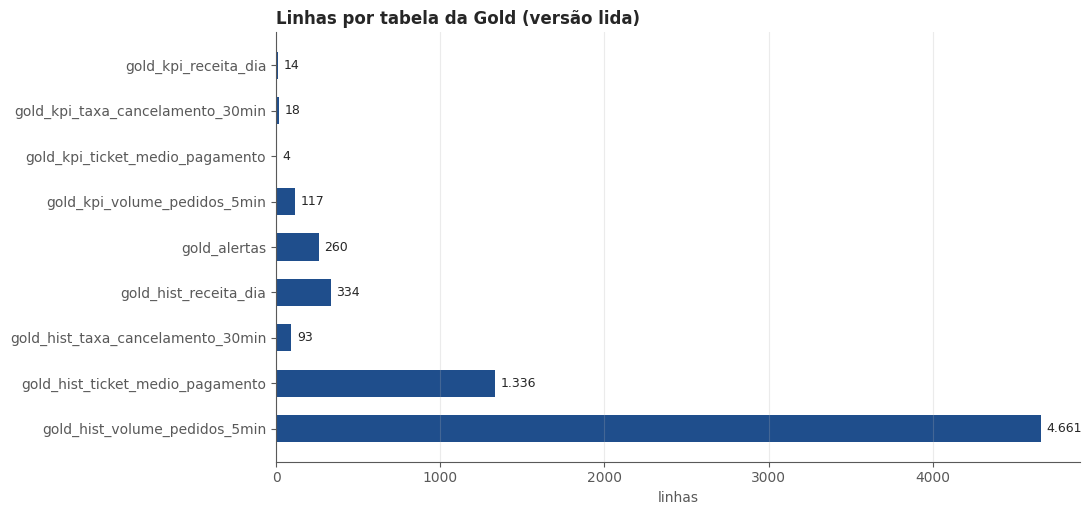

In [0]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# Padronização visual dos dashboards (Squads 1, 2 e 3)
COR = {"azul": "#1F4E8C", "azul_claro": "#5B8FC9", "card": "#D5E8F0", "eixo": "#595959", "texto": "#262626",
       "referencia": "#8C8C8C", "aberta": "#8C8C8C", "alerta": "#F2B705"}
plt.rcParams.update({"axes.edgecolor": COR["eixo"], "axes.labelcolor": COR["eixo"], "xtick.color": COR["eixo"], "ytick.color": COR["eixo"],
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": COR["texto"], "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.25,
                     "legend.frameon": False})
LINHAS_AMOSTRA = 20                                                # 6.2 e 6.4: linhas exibidas de cada tabela
brl = lambda v: f"R$ {v:,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")
ORDEM_PAPEL = {"placar (overwrite)": 0, "histórico (append)": 1, "fora do pipeline atual": 2}


def arquivos_na_versao(df):
    """Arquivos de dados que a versão lida usa (None se o ambiente não expõe essa informação)."""
    try:
        return len(df.inputFiles())
    except Exception:
        return None


itens = [p for p in fs_squad.get_paths(path=f"gold/{TABELA}", recursive=True) if not p.is_directory and p.name.count("/") >= 3]
arquivos = pd.DataFrame([(p.name.split("/")[2], p.name.rsplit("/", 1)[-1], "/_delta_log/" in p.name, p.content_length or 0, p.last_modified)
                         for p in itens], columns=["tabela", "arquivo", "no_log", "bytes", "modificado"])
dados = arquivos[~arquivos["no_log"] & arquivos["arquivo"].str.endswith(".parquet")]
commits = arquivos[arquivos["no_log"] & arquivos["arquivo"].str.fullmatch(r"\d{20}\.json")]

inventario = pd.DataFrame({"tabela": sorted(set(arquivos["tabela"]) | {n for n, df in gold.items() if df is not None})})
inventario["papel"] = inventario["tabela"].map(lambda t: "placar (overwrite)" if t in KPIS else "histórico (append)" if t in HISTORICOS
                                               else "fora do pipeline atual")
inventario = inventario.sort_values(["papel", "tabela"], key=lambda s: s.map(ORDEM_PAPEL) if s.name == "papel" else s, ignore_index=True)
inventario["arquivos_na_pasta"] = inventario["tabela"].map(dados.groupby("tabela").size()).fillna(0).astype(int)
inventario["mb_na_pasta"] = inventario["tabela"].map(dados.groupby("tabela")["bytes"].sum() / 1024 ** 2).fillna(0).round(3)
inventario["commits"] = inventario["tabela"].map(commits.groupby("tabela").size()).fillna(0).astype(int)
inventario["ultima_gravacao_utc"] = inventario["tabela"].map(arquivos.groupby("tabela")["modificado"].max()).astype(str)
conteudo = []
for nome in inventario["tabela"]:
    df = gold.get(nome)
    if df is None:
        conteudo.append({})
        continue
    medidas = [F.count("*").alias("linhas")] + ([F.countDistinct("ciclo_id").alias("ciclos")] if "ciclo_id" in df.columns else [])
    r = df.agg(*medidas).first().asDict()
    conteudo.append({"versao_lida": versoes[nome], "linhas": r["linhas"], "colunas": len(df.columns), "ciclos": r.get("ciclos"),
                     "arquivos_na_versao": arquivos_na_versao(df)})
INTEIRAS = ["versao_lida", "linhas", "colunas", "ciclos", "arquivos_na_versao"]
inventario = pd.concat([inventario, pd.DataFrame(conteudo, columns=INTEIRAS).astype("float").astype("Int64")], axis=1)
sobras = inventario.loc[inventario["papel"] == "fora do pipeline atual", "tabela"].tolist()

# ------------------------------ validação ------------------------------
registrar(6, "Passo 7 · Gold", "pastas na Gold fora das 9 tabelas do pipeline (sobras de versões antigas)", sobras or "nenhuma", not sobras,
          critico=False)

# ------------------------------ resultado ------------------------------
display(inventario)
com_linhas = inventario.dropna(subset=["linhas"]).iloc[::-1]       # barh desenha de baixo para cima
if len(com_linhas):
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(com_linhas) + 1.2))
    barras = ax.barh(com_linhas["tabela"], com_linhas["linhas"].astype(int), color=COR["azul"], height=0.6)
    ax.bar_label(barras, labels=[f"{int(v):,}".replace(",", ".") for v in com_linhas["linhas"]], padding=4, color=COR["texto"], fontsize=9)
    ax.grid(False)
    ax.xaxis.grid(True, alpha=0.25)
    ax.set(title="Linhas por tabela da Gold (versão lida)", xlabel="linhas")
    plt.tight_layout()
    plt.show()

### 6.2 Conteúdo de cada tabela
**Faz:** mostra as `LINHAS_AMOSTRA` linhas mais recentes de cada tabela da Gold, na versão lida (ordenadas por `ciclo_id` e janela, data
ou horário do alerta). A primeira coluna, `tabela`, identifica de qual tabela é cada resultado.

In [0]:
for nome in KPIS + HISTORICOS:
    df = gold[nome]
    if df is None:
        print(f"▸ {nome}: ainda não gravada")
        continue
    ordem = [c for c in ("ciclo_id", "janela_inicio", "data", "gerado_em_utc") if c in df.columns]
    linha = inventario.set_index("tabela").loc[nome]
    print(f"▸ {nome} · {linha['papel']} · {int(linha['linhas']):,} linhas · versão {versoes[nome]}".replace(",", "."))
    display(df.orderBy(*[F.desc(c) for c in ordem]).select(F.lit(nome).alias("tabela"), "*").limit(LINHAS_AMOSTRA))

▸ gold_kpi_volume_pedidos_5min · placar (overwrite) · 117 linhas · versão 333


tabela,pedidos,janela_inicio,janela_fim,no_pico,fechada,limite_x,situacao,ciclo_id
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:48:00.000Z,2026-10-15T23:53:00.000Z,false,false,1,aberta,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:47:00.000Z,2026-10-15T23:52:00.000Z,false,false,1,aberta,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:46:00.000Z,2026-10-15T23:51:00.000Z,false,false,1,aberta,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:45:00.000Z,2026-10-15T23:50:00.000Z,false,true,1,fora_do_pico,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:44:00.000Z,2026-10-15T23:49:00.000Z,false,true,1,fora_do_pico,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:43:00.000Z,2026-10-15T23:48:00.000Z,false,true,1,fora_do_pico,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:42:00.000Z,2026-10-15T23:47:00.000Z,false,true,1,fora_do_pico,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:41:00.000Z,2026-10-15T23:46:00.000Z,false,true,1,fora_do_pico,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:40:00.000Z,2026-10-15T23:45:00.000Z,false,true,1,fora_do_pico,20261016025738
gold_kpi_volume_pedidos_5min,0,2026-10-15T23:39:00.000Z,2026-10-15T23:44:00.000Z,false,true,1,fora_do_pico,20261016025738


▸ gold_kpi_ticket_medio_pagamento · placar (overwrite) · 4 linhas · versão 333


tabela,metodo_pagamento,janela_inicio,janela_fim,pedidos,receita,ticket_medio,media_historica,desvio_pct,situacao,ciclo_id
gold_kpi_ticket_medio_pagamento,cartão crédito,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,32,7967.0,248.97,255.95,-2.7,nao_monitorado,20261016025738
gold_kpi_ticket_medio_pagamento,cartão débito,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,28,7947.35,283.83,295.65,-4.0,nao_monitorado,20261016025738
gold_kpi_ticket_medio_pagamento,boleto,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,21,4445.38,211.68,251.36,-15.8,nao_monitorado,20261016025738
gold_kpi_ticket_medio_pagamento,pix,2026-10-15T10:05:56.050Z,2026-10-15T11:05:56.050Z,32,8463.28,264.48,268.52,-1.5,normal,20261016025738


▸ gold_kpi_taxa_cancelamento_30min · placar (overwrite) · 18 linhas · versão 333


...

tabela,janela_inicio,janela_fim,pedidos,cancelados,taxa_pct,volume_suficiente,fechada,situacao,ciclo_id
gold_hist_taxa_cancelamento_30min,2026-10-14T11:15:00.000Z,2026-10-14T11:45:00.000Z,1,0,0.0,null,true,normal,20261016023945
gold_hist_taxa_cancelamento_30min,2026-10-14T11:10:00.000Z,2026-10-14T11:40:00.000Z,1,0,0.0,null,true,normal,20261016023945
gold_hist_taxa_cancelamento_30min,2026-10-15T10:30:00.000Z,2026-10-15T11:00:00.000Z,51,2,3.92,null,true,normal,20261015140624
gold_hist_taxa_cancelamento_30min,2026-10-15T10:25:00.000Z,2026-10-15T10:55:00.000Z,60,3,5.0,null,true,normal,20261015140049
gold_hist_taxa_cancelamento_30min,2026-10-15T10:20:00.000Z,2026-10-15T10:50:00.000Z,55,3,5.45,null,true,normal,20261015135531
gold_hist_taxa_cancelamento_30min,2026-10-15T10:15:00.000Z,2026-10-15T10:45:00.000Z,55,4,7.27,null,true,normal,20261015135000
gold_hist_taxa_cancelamento_30min,2026-10-15T10:10:00.000Z,2026-10-15T10:40:00.000Z,47,3,6.38,null,true,normal,20261015134433
gold_hist_taxa_cancelamento_30min,2026-10-15T10:05:00.000Z,2026-10-15T10:35:00.000Z,36,2,5.56,null,true,normal,20261015133902
gold_hist_taxa_cancelamento_30min,2026-10-15T10:00:00.000Z,2026-10-15T10:30:00.000Z,34,2,5.88,null,true,normal,20261015133609
gold_hist_taxa_cancelamento_30min,2026-10-15T09:55:00.000Z,2026-10-15T10:25:00.000Z,19,1,5.26,null,true,normal,20261015133049


▸ gold_hist_receita_dia · histórico (append) · 334 linhas · versão 333


tabela,data,receita_acumulada,receita_sem_cancelados,atualizado_ate,receita_semana_anterior,variacao_pct,situacao,ciclo_id
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17243.97,67.1,alerta,20261016025738
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17243.97,67.1,alerta,20261016023945
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016021633
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016020141
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016014702
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016013132
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016011633
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016010133
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016004633
gold_hist_receita_dia,2026-10-15T00:00:00.000Z,28823.01,null,2026-10-15T11:05:56.050Z,17175.2,67.8,alerta,20261016003135


▸ gold_alertas · histórico (append) · 260 linhas · versão 53


tabela,ciclo_id,gerado_em_utc,regra,indicador,chave,mensagem,valor,limite
gold_alertas,20261016023945,2026-10-16T02:39:45.503Z,9,gold_kpi_receita_dia,9|2026-10-14|23,Receita fora do padrão da semana anterior,-98.7%,±30%
gold_alertas,20261016023945,2026-10-16T02:39:45.503Z,9,gold_kpi_receita_dia,9|2026-10-09|23,Receita fora do padrão da semana anterior,-99.6%,±30%
gold_alertas,20261016023945,2026-10-16T02:39:45.503Z,9,gold_kpi_receita_dia,9|2026-10-13|23,Receita fora do padrão da semana anterior,-85.0%,±30%
gold_alertas,20261016023945,2026-10-16T02:39:45.503Z,9,gold_kpi_receita_dia,9|2026-10-12|23,Receita fora do padrão da semana anterior,-96.7%,±30%
gold_alertas,20261016023945,2026-10-16T02:39:45.503Z,9,gold_kpi_receita_dia,9|2026-10-10|23,Receita fora do padrão da semana anterior,-98.2%,±30%
gold_alertas,20261016023945,2026-10-16T02:39:45.503Z,9,gold_kpi_receita_dia,9|2026-10-11|23,Receita fora do padrão da semana anterior,-93.4%,±30%
gold_alertas,20261015143200,2026-10-15T14:32:00.913Z,6,gold_kpi_volume_pedidos_5min,6|2026-10-15 11:06:00,Volume abaixo de X no horário de pico,"mín. 0 pedidos/5 min, por 15 min (até 11:25)",1
gold_alertas,20261015140917,2026-10-15T14:09:17.209Z,5,quarantine,5|real-time-data/2026/10/15/110802/ecommerce_pedidos.parquet,Status fora dos valores permitidos,1 pedidos (id_pedido: 1792073280),0
gold_alertas,20261015140624,2026-10-15T14:06:24.667Z,5,quarantine,5|real-time-data/2026/10/15/110402/ecommerce_pedidos.parquet,Status fora dos valores permitidos,"2 pedidos (id_pedido: 1792073052, 1792073054)",0
gold_alertas,20261015140624,2026-10-15T14:06:24.667Z,10,quarantine,10|real-time-data/2026/10/15/110402/ecommerce_pedidos.parquet,Atualização de status anterior ao pedido,1 pedidos (id_pedido: 1792073045),0


### 6.3 Fotografia atual e placares
**Faz:** desenha, no padrão dos dashboards, os cards com o valor mais recente de cada KPI (na linha de cima) e os quatro placares da
versão lida (abaixo). São os mesmos números recalculados na Etapa 4.

| Gráfico | Como ler |
|---|---|
| Regra 6 | linha azul: pedidos nos 5 min anteriores a cada minuto (com o placar pelo relógio, minutos sem pedido aparecem como zero); tracejado: X; pontos amarelos: janelas em alerta; faixa cinza: janelas ainda abertas |
| Regra 7 | por método: ticket da última hora (azul, rótulo com o desvio) × média histórica (azul claro); amarelo: Pix em alerta |
| Regra 8 | linha azul: % cancelado nos 30 min anteriores, a cada 5 min (janela deslizante; a linha se interrompe onde não houve pedido); tracejado: limite de 10%; pontos amarelos: alerta; faixa cinza: janelas ainda abertas |
| Regra 9 | por dia: receita (azul, rótulo com a variação) × mesmo dia da semana anterior (azul claro); amarelo: fora de ±30% |

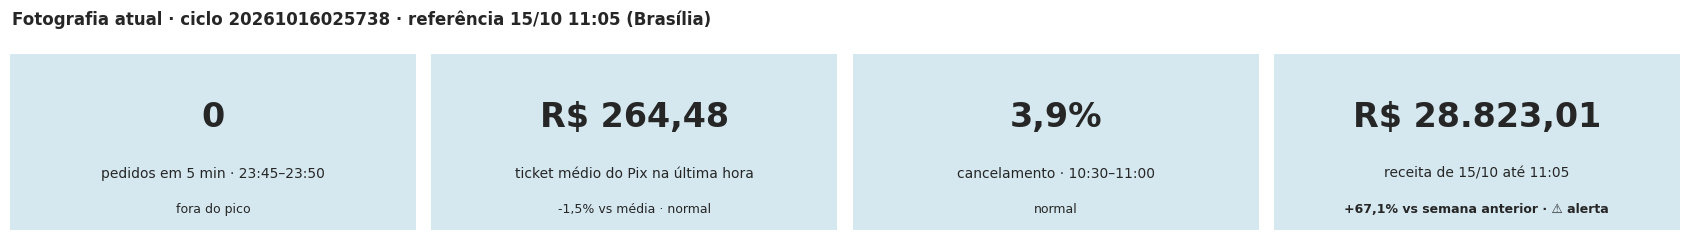

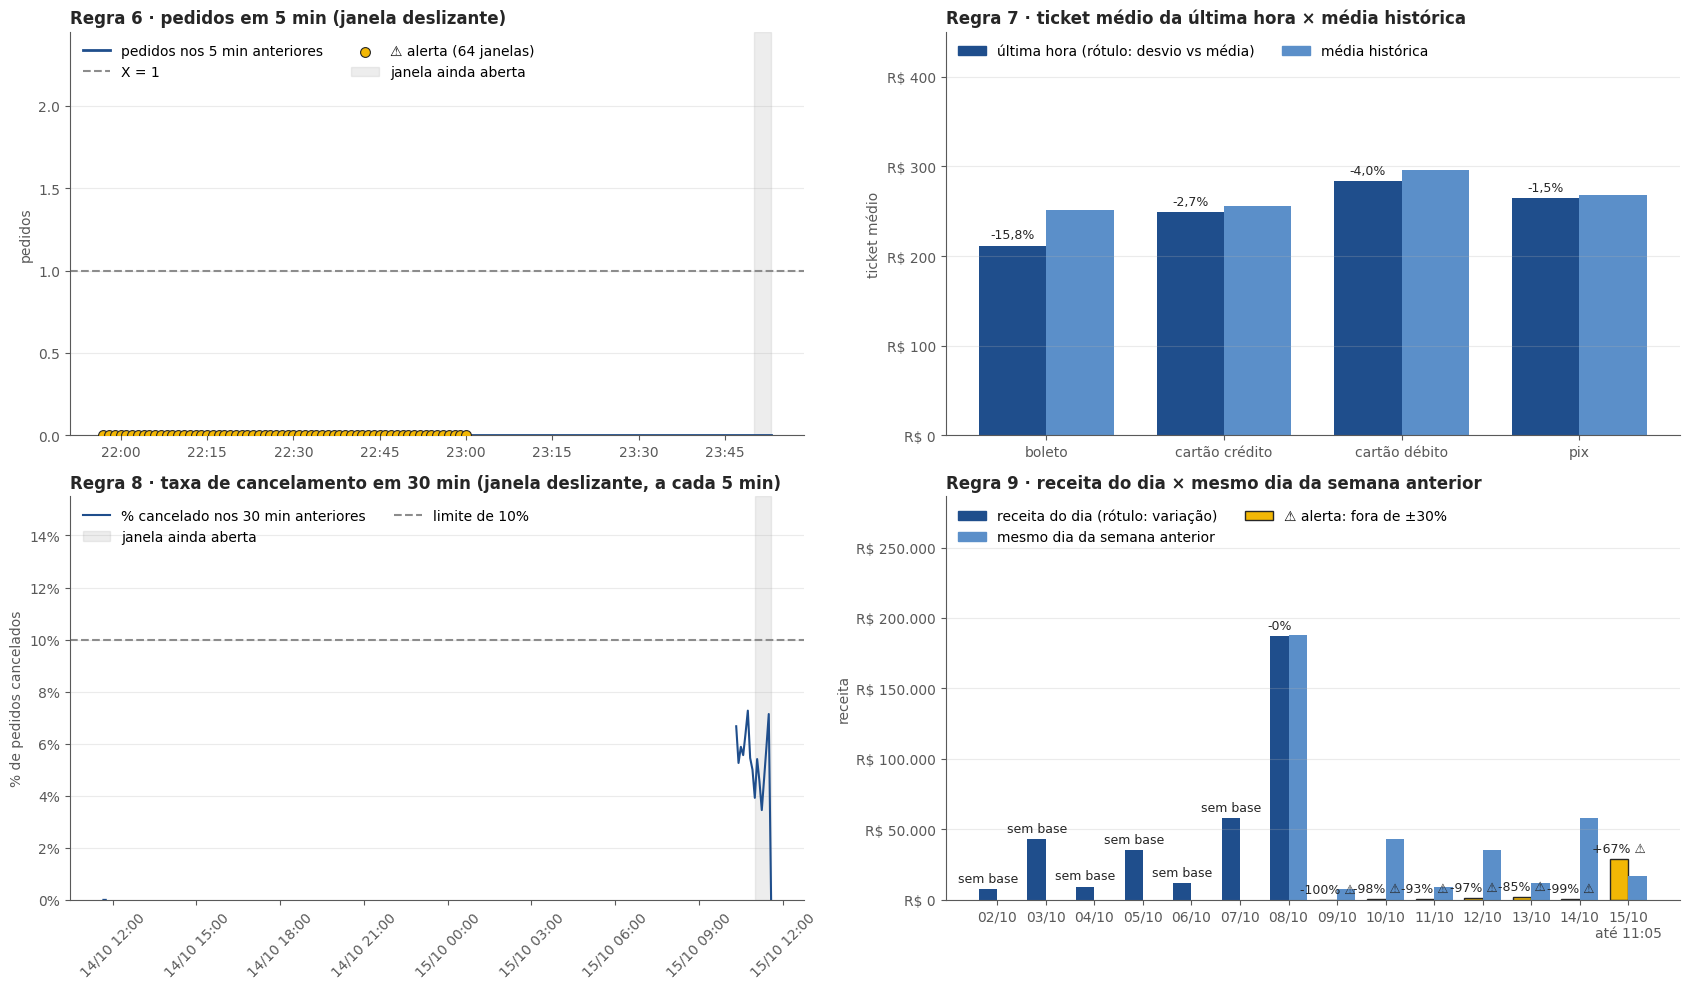

In [0]:
situacao_texto = lambda s: "⚠ alerta" if s == "alerta" else str(s).replace("_", " ")
fechadas6 = vol[vol["fechada"]]
ult6 = fechadas6.iloc[-1] if len(fechadas6) else vol.iloc[-1]
fechadas8 = canc[canc["fechada"].astype(bool)].sort_values("janela_inicio")
ult8 = fechadas8.iloc[-1] if len(fechadas8) else canc.sort_values("janela_inicio").iloc[-1]
hoje = rec.sort_values("data").iloc[-1]
pix = tic[tic["metodo_pagamento"] == CRITERIOS["metodo_monitorado"]]


def card_pix():
    if pix.empty or pd.isna(pix["ticket_medio"].iloc[0]):
        return "—", "ticket médio do Pix na última hora", "sem pedidos Pix"
    p = pix.iloc[0]
    desvio = f"{p['desvio_pct']:+.1f}% vs média · ".replace(".", ",") if pd.notna(p["desvio_pct"]) else ""
    return brl(p["ticket_medio"]), "ticket médio do Pix na última hora", desvio + situacao_texto(p["situacao"])


variacao_hoje = f"{hoje['variacao_pct']:+.1f}% vs semana anterior · ".replace(".", ",") if pd.notna(hoje["variacao_pct"]) else ""
cards = [
    (f"{int(ult6['pedidos'])}", f"pedidos em 5 min · {ult6['janela_inicio']:%H:%M}–{ult6['janela_fim']:%H:%M}", situacao_texto(ult6["situacao"])),
    card_pix(),
    (f"{ult8['taxa_pct']:.1f}%".replace(".", ","), f"cancelamento · {ult8['janela_inicio']:%H:%M}–{ult8['janela_fim']:%H:%M}",
     situacao_texto(ult8["situacao"])),
    (brl(hoje["receita_acumulada"]), f"receita de {hoje['data']:%d/%m} até {pd.Timestamp(hoje['atualizado_ate']):%H:%M}",
     variacao_hoje + situacao_texto(hoje["situacao"])),
]

# ------------------------------ resultado: cards ------------------------------
fig, eixos = plt.subplots(1, 4, figsize=(17, 2.4))
for ax, (numero, rotulo, situacao) in zip(eixos, cards):
    ax.set_facecolor(COR["card"])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.text(0.5, 0.64, numero, ha="center", va="center", fontsize=24, fontweight="bold", color=COR["texto"], transform=ax.transAxes)
    ax.text(0.5, 0.32, rotulo, ha="center", va="center", fontsize=10, color=COR["texto"], transform=ax.transAxes)
    ax.text(0.5, 0.12, situacao, ha="center", va="center", fontsize=9, color=COR["texto"], transform=ax.transAxes,
            fontweight="bold" if "alerta" in situacao else "normal")
fig.suptitle(f"Fotografia atual · ciclo {ciclo_de['gold_kpi_volume_pedidos_5min']} · referência {referencia:%d/%m %H:%M} (Brasília)",
             x=0.01, ha="left", fontweight="bold", color=COR["texto"])
plt.tight_layout()
plt.show()

# ------------------------------ resultado: placares ------------------------------
fig, ((a6, a7), (a8, a9)) = plt.subplots(2, 2, figsize=(17, 10))
larg = 0.38

# Regra 6: volume em 5 min, com X e as janelas em alerta
a6.plot(vol["janela_fim"], vol["pedidos"], color=COR["azul"], linewidth=2, label="pedidos nos 5 min anteriores")
a6.axhline(CRITERIOS["x_regra6"], color=COR["referencia"], linestyle="--", linewidth=1.5, label=f"X = {CRITERIOS['x_regra6']}")
em_alerta6 = vol[vol["situacao"] == "alerta"]
if len(em_alerta6):
    a6.scatter(em_alerta6["janela_fim"], em_alerta6["pedidos"], s=50, color=COR["alerta"], edgecolor=COR["texto"], linewidth=0.8, zorder=3,
               label=f"⚠ alerta ({len(em_alerta6)} janelas)")
abertas6 = vol[~vol["fechada"]]
if len(abertas6):
    a6.axvspan(abertas6["janela_fim"].min() - pd.Timedelta(minutes=1), abertas6["janela_fim"].max(), color=COR["aberta"], alpha=0.15,
               label="janela ainda aberta")
a6.set_ylim(0, max(vol["pedidos"].max(), CRITERIOS["x_regra6"]) * 1.45 + 1)            # espaço para a legenda
a6.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
a6.set(title="Regra 6 · pedidos em 5 min (janela deslizante)", ylabel="pedidos")
a6.legend(loc="upper left", ncol=2)

# Regra 7: ticket da última hora × média histórica, por método
t7 = tic.sort_values("metodo_pagamento").reset_index(drop=True)
pos7 = np.arange(len(t7))
alerta7 = (t7["situacao"] == "alerta").tolist()
b7 = a7.bar(pos7 - larg / 2, t7["ticket_medio"].fillna(0), larg, color=[COR["alerta"] if a else COR["azul"] for a in alerta7],
            edgecolor=[COR["texto"] if a else "none" for a in alerta7])
a7.bar(pos7 + larg / 2, t7["media_historica"].fillna(0), larg, color=COR["azul_claro"])
a7.bar_label(b7, labels=[("—" if pd.isna(d) else f"{d:+.1f}%".replace(".", ",")) + (" ⚠" if a else "") for d, a in zip(t7["desvio_pct"], alerta7)],
             padding=3, fontsize=9, color=COR["texto"])
a7.set_xticks(pos7)
a7.set_xticklabels(t7["metodo_pagamento"].fillna("(vazio)"))
a7.yaxis.set_major_formatter(FuncFormatter(lambda v, _: brl(v)[:-3]))
a7.set(title="Regra 7 · ticket médio da última hora × média histórica", ylabel="ticket médio")
legenda7 = [Patch(color=COR["azul"], label="última hora (rótulo: desvio vs média)"), Patch(color=COR["azul_claro"], label="média histórica")]
if any(alerta7):
    legenda7.append(Patch(facecolor=COR["alerta"], edgecolor=COR["texto"], label="⚠ alerta: Pix mais de 30% abaixo da média"))
a7.legend(handles=legenda7, loc="upper left", ncol=2)
a7.set_ylim(top=a7.get_ylim()[1] * 1.45)

# Regra 8: taxa de cada janela deslizante de 30 min, marcada no fim da janela; a linha se interrompe onde não houve pedido
c8 = canc.sort_values("janela_fim").reset_index(drop=True)
if len(c8):
    linha8 = c8.set_index("janela_fim")["taxa_pct"].reindex(pd.date_range(c8["janela_fim"].min(), c8["janela_fim"].max(),
                                                                          freq=CRITERIOS["passo_cancelamento"]))
    a8.plot(linha8.index, linha8.values, color=COR["azul"], linewidth=1.5, label="% cancelado nos 30 min anteriores")
em_alerta8 = c8[c8["situacao"] == "alerta"]
if len(em_alerta8):
    a8.scatter(em_alerta8["janela_fim"], em_alerta8["taxa_pct"], s=50, color=COR["alerta"], edgecolor=COR["texto"], linewidth=0.8, zorder=3,
               label=f"⚠ alerta ({len(em_alerta8)} janelas)")
abertas8 = c8[~c8["fechada"].astype(bool)]
if len(abertas8):
    a8.axvspan(abertas8["janela_fim"].min() - PASSO8, abertas8["janela_fim"].max(), color=COR["aberta"], alpha=0.15, label="janela ainda aberta")
a8.axhline(CRITERIOS["cancelamento_max_pct"], color=COR["referencia"], linestyle="--", linewidth=1.5,
           label=f"limite de {CRITERIOS['cancelamento_max_pct']}%")
a8.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
a8.tick_params(axis="x", rotation=45)
a8.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
a8.set(title="Regra 8 · taxa de cancelamento em 30 min (janela deslizante, a cada 5 min)", ylabel="% de pedidos cancelados")
a8.legend(loc="upper left", ncol=2)
a8.set_ylim(0, max(c8["taxa_pct"].max() if len(c8) else 0, CRITERIOS["cancelamento_max_pct"]) * 1.45 + 1)

# Regra 9: receita do dia × mesmo dia da semana anterior
r9 = rec.sort_values("data").reset_index(drop=True)
pos9 = np.arange(len(r9))
alerta9 = (r9["situacao"] == "alerta").tolist()
b9 = a9.bar(pos9 - larg / 2, r9["receita_acumulada"], larg, color=[COR["alerta"] if a else COR["azul"] for a in alerta9],
            edgecolor=[COR["texto"] if a else "none" for a in alerta9])
a9.bar(pos9 + larg / 2, r9["receita_semana_anterior"].fillna(0), larg, color=COR["azul_claro"])
a9.bar_label(b9, labels=[("sem base" if pd.isna(v) else f"{v:+.0f}%") + (" ⚠" if a else "") for v, a in zip(r9["variacao_pct"], alerta9)],
             padding=3, fontsize=9, color=COR["texto"])
a9.set_xticks(pos9)
a9.set_xticklabels([f"{d:%d/%m}" + (f"\naté {pd.Timestamp(a):%H:%M}" if i == len(r9) - 1 else "")
                    for i, (d, a) in enumerate(zip(r9["data"], r9["atualizado_ate"]))])
a9.yaxis.set_major_formatter(FuncFormatter(lambda v, _: brl(v)[:-3]))
a9.set(title="Regra 9 · receita do dia × mesmo dia da semana anterior", ylabel="receita")
legenda9 = [Patch(color=COR["azul"], label="receita do dia (rótulo: variação)"), Patch(color=COR["azul_claro"], label="mesmo dia da semana anterior")]
if any(alerta9):
    legenda9.append(Patch(facecolor=COR["alerta"], edgecolor=COR["texto"], label=f"⚠ alerta: fora de ±{CRITERIOS['variacao_receita_pct']}%"))
a9.legend(handles=legenda9, loc="upper left", ncol=2)
a9.set_ylim(top=a9.get_ylim()[1] * 1.45)

plt.tight_layout()
plt.show()

### 6.4 Mural de alertas
**Faz:** conta os alertas publicados por regra e mostra os `LINHAS_AMOSTRA` mais recentes do `gold_alertas` (versão lida).

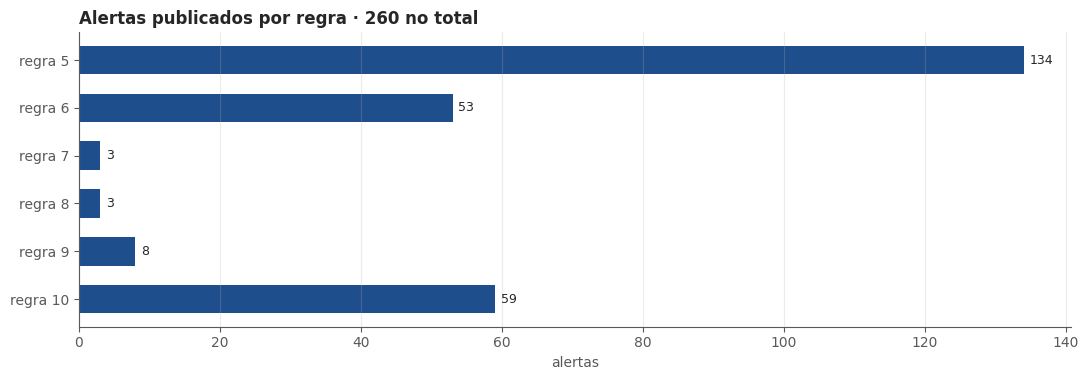

gerado_em_utc,regra,mensagem,valor,limite,chave
2026-10-16T02:39:45.503Z,9,Receita fora do padrão da semana anterior,-98.7%,±30%,9|2026-10-14|23
2026-10-16T02:39:45.503Z,9,Receita fora do padrão da semana anterior,-99.6%,±30%,9|2026-10-09|23
2026-10-16T02:39:45.503Z,9,Receita fora do padrão da semana anterior,-98.2%,±30%,9|2026-10-10|23
2026-10-16T02:39:45.503Z,9,Receita fora do padrão da semana anterior,-93.4%,±30%,9|2026-10-11|23
2026-10-16T02:39:45.503Z,9,Receita fora do padrão da semana anterior,-96.7%,±30%,9|2026-10-12|23
2026-10-16T02:39:45.503Z,9,Receita fora do padrão da semana anterior,-85.0%,±30%,9|2026-10-13|23
2026-10-15T14:32:00.913Z,6,Volume abaixo de X no horário de pico,"mín. 0 pedidos/5 min, por 15 min (até 11:25)",1,6|2026-10-15 11:06:00
2026-10-15T14:09:17.209Z,5,Status fora dos valores permitidos,1 pedidos (id_pedido: 1792073280),0,5|real-time-data/2026/10/15/110802/ecommerce_pedidos.parquet
2026-10-15T14:06:24.667Z,5,Status fora dos valores permitidos,"2 pedidos (id_pedido: 1792073052, 1792073054)",0,5|real-time-data/2026/10/15/110402/ecommerce_pedidos.parquet
2026-10-15T14:06:24.667Z,10,Atualização de status anterior ao pedido,1 pedidos (id_pedido: 1792073045),0,10|real-time-data/2026/10/15/110402/ecommerce_pedidos.parquet


In [0]:
if len(alertas):
    por_regra = alertas.groupby("regra").size().sort_index(ascending=False)
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(por_regra) + 1.2))
    barras = ax.barh([f"regra {int(r)}" for r in por_regra.index], por_regra.values, color=COR["azul"], height=0.6)
    ax.bar_label(barras, padding=4, color=COR["texto"], fontsize=9)
    ax.grid(False)
    ax.xaxis.grid(True, alpha=0.25)
    ax.set(title=f"Alertas publicados por regra · {len(alertas):,} no total".replace(",", "."), xlabel="alertas")
    plt.tight_layout()
    plt.show()
    colunas = [c for c in ("gerado_em_utc", "regra", "mensagem", "valor", "limite", "chave") if c in alertas.columns]
    display(alertas.sort_values("gerado_em_utc", ascending=False)[colunas].head(LINHAS_AMOSTRA))
else:
    print("Mural de alertas vazio.")

## Etapa 7 — Veredito
**Faz:** junta as verificações das Etapas 2 a 6 por requisito do plano e da planilha.
**Valida:** sem nenhum ❌, o que foi gravado nas três camadas e no SQL Server cumpre o plano e a planilha; ⚠️ são pendências
(uma camada ainda não processou o último lote, espelho atrasado) ou achados para levar ao Geovany.

In [0]:
ORDEM = ["Passo 5 · Bronze", "Regra 1 · schema", "Regra 2 · uma vez só", "Passo 6 · Silver", "Regras 3, 4, 5 e 10 · quarentena",
         "Regra 6 · volume 5 min", "Regra 7 · ticket médio", "Regra 8 · cancelamento", "Regra 9 · receita do dia",
         "Alertas (regras 5 a 10)", "Passo 7 · Gold", "Passo 7 · SQL Server"]
veredito = pd.DataFrame(validacao, columns=["etapa", "requisito", "verificacao", "resultado", "situacao"])
pior = lambda s: "❌" if (s == "❌").any() else ("⚠️" if (s == "⚠️").any() else "✅")
por_requisito = (veredito.groupby("requisito")
                 .agg(situacao=("situacao", pior), verificacoes=("situacao", "size"), com_falha=("situacao", lambda s: int((s != "✅").sum())))
                 .reindex([r for r in ORDEM if r in set(veredito["requisito"])]).reset_index())
contagem = veredito["situacao"].value_counts().to_dict()
_silver_no_ciclo.clear()

# ------------------------------ validação ------------------------------
checar(contagem.get("❌", 0) == 0,
       f"ENTREGA VALIDADA: {contagem.get('✅', 0)} verificações ok · {contagem.get('⚠️', 0)} avisos · versões lidas: Bronze {v_bronze}, Silver {v_silver}",
       f"{contagem.get('❌', 0)} inconsistências nos dados: veja as linhas com ❌", parar=False)

# ------------------------------ resultado ------------------------------
display(por_requisito)
display(veredito.sort_values("situacao", key=lambda s: s.map({"❌": 0, "⚠️": 1, "✅": 2}), kind="stable", ignore_index=True))

✅ ENTREGA VALIDADA: 77 verificações ok · 6 avisos · versões lidas: Bronze 68, Silver 59


requisito,situacao,verificacoes,com_falha
Passo 5 · Bronze,⚠️,6,1
Regra 1 · schema,✅,3,0
Regra 2 · uma vez só,✅,2,0
Passo 6 · Silver,⚠️,8,1
"Regras 3, 4, 5 e 10 · quarentena",✅,3,0
Regra 6 · volume 5 min,✅,7,0
Regra 7 · ticket médio,✅,2,0
Regra 8 · cancelamento,✅,4,0
Regra 9 · receita do dia,✅,2,0
Alertas (regras 5 a 10),⚠️,12,4


etapa,requisito,verificacao,resultado,situacao
2,Passo 5 · Bronze,Bronze: gravações só em append,1 de 69 fora de append: v31 overwrite em 08/10 18:28 UTC (1.946 linhas),⚠️
3,Passo 6 · Silver,quarentena: gravações só em append,1 de 44 fora de append: v43 overwrite em 16/10 02:38 UTC (208 linhas) [reprocesso_regra5],⚠️
4,Alertas (regras 5 a 10),"regra 5: falha histórica, entre o 1º alerta (07/10 00:38:44 UTC) e a correção do 05 (12/10 01:15 UTC)",7 · processados entre 07/10 12:28:23 e 07/10 13:50:38 UTC,⚠️
4,Alertas (regras 5 a 10),"regra 5: micro-lotes reprovados antes do 1º alerta da regra, sem alerta (legado)",17 · processados entre 06/10 21:49:00 e 06/10 21:49:00 UTC,⚠️
4,Alertas (regras 5 a 10),"regra 10: falha histórica, entre o 1º alerta (07/10 00:38:44 UTC) e a correção do 05 (12/10 01:15 UTC)",11 · processados entre 07/10 12:32:16 e 07/10 13:50:38 UTC,⚠️
4,Alertas (regras 5 a 10),"regra 10: micro-lotes reprovados antes do 1º alerta da regra, sem alerta (legado)",46 · processados entre 06/10 21:49:00 e 06/10 21:49:00 UTC,⚠️
2,Regra 1 · schema,colunas obrigatórias na Bronze,as 6 presentes,✅
2,Regra 1 · schema,tipos iguais aos do contrato da EDA,todos,✅
2,Regra 1 · schema,micro-lotes recusados pela Bronze (motivos abaixo),0,✅
2,Regra 2 · uma vez só,micro-lotes com mais de uma ingestão na Bronze,0,✅
